In [1]:
import pandas as pd

df = pd.read_csv("Data_MLB_2025_StatcastPostseason_PitchByPitch_20251102a.csv")

df.head()


,game_year,game_date,player_name,pitcher,batter,balls,strikes,inning,inning_topbot,at_bat_number,...,post_home_score,post_bat_score,post_fld_score,if_fielding_alignment,of_fielding_alignment,spin_axis,delta_home_win_exp,delta_run_exp,bat_speed,swing_length
0,2025,2025-09-30,"Ashcraft, Graham",668933,605141,0,0,8,Bot,73,...,10,10,5,Standard,Standard,42.0,0.0,0.041,NaN,NaN
1,2025,2025-09-30,"Ashcraft, Graham",668933,605141,1,0,8,Bot,73,...,10,10,5,Standard,Standard,201.0,0.0,-0.050,NaN,NaN
2,2025,2025-09-30,"Ashcraft, Graham",668933,605141,1,1,8,Bot,73,...,10,10,5,Standard,Standard,23.0,0.0,-0.061,65.0,6.0
3,2025,2025-09-30,"Ashcraft, Graham",668933,605141,1,2,8,Bot,73,...,10,10,5,Standard,Standard,39.0,0.0,0.000,53.1,7.2
4,2025,2025-09-30,"Ashcraft, Graham",668933,605141,1,2,8,Bot,73,...,10,10,5,Standard,Standard,201.0,0.0,0.043,NaN,NaN


In [2]:
df.shape

(14096, 95)

In [3]:
df["pitching_team"] = df["home_team"].where(
    df["inning_topbot"] == "Top",
    df["away_team"]
)

df[[
    "player_name",
    "pitcher",
    "pitching_team"
]].head(10)

,player_name,pitcher,pitching_team
0,"Ashcraft, Graham",668933,CIN
1,"Ashcraft, Graham",668933,CIN
2,"Ashcraft, Graham",668933,CIN
3,"Ashcraft, Graham",668933,CIN
4,"Ashcraft, Graham",668933,CIN
5,"Ashcraft, Graham",668933,CIN
6,"Ashcraft, Graham",668933,CIN
7,"Ashcraft, Graham",668933,CIN
8,"Ashcraft, Graham",668933,CIN
9,"Ashcraft, Graham",668933,CIN


In [4]:
df["pitching_team"].unique()

<ArrowStringArray>
['CIN', 'NYY', 'CHC', 'BOS', 'LAD',  'SD', 'CLE', 'DET', 'MIL', 'SEA', 'TOR',
 'PHI']
Length: 12, dtype: str

So here we need to figure out what rows actually contribute to our wOBA allowed. Not every pitch matters

In [5]:
df[[
    "pitcher",
    "pitching_team",
    "events",
    "woba_value",
    "woba_denom"
]].head(15)

,pitcher,pitching_team,events,woba_value,woba_denom
0,668933,CIN,NaN,NaN,NaN
1,668933,CIN,NaN,NaN,NaN
2,668933,CIN,NaN,NaN,NaN
3,668933,CIN,NaN,NaN,NaN
4,668933,CIN,NaN,NaN,NaN
5,668933,CIN,single,0.9,1.0
6,668933,CIN,NaN,NaN,NaN
7,668933,CIN,NaN,NaN,NaN
8,668933,CIN,NaN,NaN,NaN
9,668933,CIN,single,0.9,1.0


In [6]:
df["woba_denom"].value_counts(dropna=False)

woba_denom
NaN    10505
1.0     3564
0.0       27
Name: count, dtype: int64

We make a new table 

In [7]:
df_woba = df[df["woba_denom"] == 1].copy()


In [8]:
df_woba.shape

(3564, 96)

In [9]:
df_woba[[
    "pitcher",
    "pitching_team",
    "events",
    "woba_value",
    "woba_denom"
]].head(10)

,pitcher,pitching_team,events,woba_value,woba_denom
5,668933,CIN,single,0.9,1.0
9,668933,CIN,single,0.9,1.0
12,668933,CIN,field_out,0.0,1.0
15,668933,CIN,field_out,0.0,1.0
19,668933,CIN,hit_by_pitch,0.7,1.0
24,668933,CIN,force_out,0.0,1.0
29,605130,CIN,strikeout,0.0,1.0
36,605130,CIN,strikeout,0.0,1.0
40,605130,CIN,strikeout,0.0,1.0
49,605130,CIN,field_out,0.0,1.0


In [10]:
pitcher_woba = df_woba.groupby(
    ["pitcher", "player_name", "pitching_team"]
).agg(
    total_woba_value=("woba_value", "sum"),
    total_pa_faced=("woba_denom", "sum"),
    games_played=("game_pk", "nunique")
).reset_index()

We add all the woba value up and group by the batters names

In [11]:
pitcher_woba["woba_allowed"] = (
    pitcher_woba["total_woba_value"] /
    pitcher_woba["total_pa_faced"]
)

In [12]:
pitcher_woba.head(10)

,pitcher,player_name,pitching_team,total_woba_value,total_pa_faced,games_played,woba_allowed
0,453286,"Scherzer, Max",TOR,19.00,58.0,3,0.327586
1,458677,"Wilson, Justin",BOS,0.00,5.0,1,0.000000
2,477132,"Kershaw, Clayton",LAD,10.25,13.0,2,0.788462
3,500779,"Quintana, Jose",MIL,10.05,25.0,2,0.402000
4,502085,"Robertson, David",PHI,1.60,3.0,1,0.533333
5,506433,"Darvish, Yu",SD,4.65,7.0,1,0.664286
6,518585,"Cruz, Fernando",NYY,4.45,16.0,4,0.278125
7,519141,"Pomeranz, Drew",CHC,2.00,19.0,6,0.105263
8,547973,"Chapman, Aroldis",BOS,3.60,11.0,2,0.327273
9,552640,"Kittredge, Andrew",CHC,7.75,21.0,5,0.369048


Gonna check for blue jays

In [13]:
blue_jays_woba = pitcher_woba[
    pitcher_woba["pitching_team"] == "TOR"
]

blue_jays_woba

,pitcher,player_name,pitching_team,total_woba_value,total_pa_faced,games_played,woba_allowed
0,453286,"Scherzer, Max",TOR,19.00,58.0,3,0.327586
14,592332,"Gausman, Kevin",TOR,27.75,116.0,6,0.239224
25,605135,"Bassitt, Chris",TOR,4.10,30.0,7,0.136667
40,622554,"Domínguez, Seranthony",TOR,15.10,49.0,12,0.308163
44,641778,"Lauer, Eric",TOR,7.15,33.0,5,0.216667
55,656546,"Hoffman, Jeff",TOR,9.65,46.0,10,0.209783
68,663893,"Little, Brendon",TOR,12.00,23.0,6,0.521739
74,667297,"Nance, Tommy",TOR,4.85,9.0,2,0.538889
82,669456,"Bieber, Shane",TOR,29.05,82.0,5,0.354268
104,677865,"Bruihl, Justin",TOR,3.80,4.0,1,0.950000


In [14]:
print("Total postseason hitters:", pitcher_woba["pitcher"].nunique())
print("Blue Jays hitters:", blue_jays_woba["pitcher"].nunique())
print("Total qualifying opportunities:", pitcher_woba["total_pa_faced"].sum())
print("Missing names:",
      pitcher_woba["player_name"].isna().sum())

print("Duplicate pitcher-team rows:",
      pitcher_woba.duplicated(["pitcher", "pitching_team"]).sum())

Total postseason hitters: 143
Blue Jays hitters: 15
Total qualifying opportunities: 3564.0
Missing names: 0
Duplicate pitcher-team rows: 0


We have to  keep total_pa for later cuz some batters have low denominators or opportunities, so their postseason woba may be higher simply cuz the denominator is lower

So far, we've cleaned the postseason dataset, identified the teams, and calculated each batter's postseason wOBA with their name and ID. Next, we'll find a 2025 salary dataset and merge it with our results. We'll also calculate pitchers' wOBA allowed. Finally, we'll compare Blue Jays players with similarly paid players. from other postseason teams to see who overperformed or underperformed.

PHASE 2

In [15]:
salary_df = pd.read_csv(
    "players_2025_combined.csv"
)

salary_df.head()

,year,team,player,position_raw,position_primary_code,position_primary_label,salary_usd,war
0,2025,NYM,Juan Soto,rf,rf,RF,61875000,5.8
1,2025,PHI,Zack Wheeler,rhp-s,rhp,RHP,42000000,4.0
2,2025,TEX,Jacob deGrom,rhp-s,rhp,RHP,40000000,3.4
3,2025,NYY,Aaron Judge,rf-dh,rf,RF,40000000,10.1
4,2025,NaN,Anthony Rendon,3b,3b,3B,38571429,NaN


In [16]:
salary_df.shape
salary_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 971 entries, 0 to 970
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   year                    971 non-null    int64  
 1   team                    874 non-null    str    
 2   player                  971 non-null    str    
 3   position_raw            971 non-null    str    
 4   position_primary_code   971 non-null    str    
 5   position_primary_label  971 non-null    str    
 6   salary_usd              971 non-null    int64  
 7   war                     874 non-null    float64
dtypes: float64(1), int64(2), str(5)
memory usage: 83.3 KB


Cleaning the new salary dataset, keeping the only relevant columns

In [17]:
salary_df = salary_df[
    ["year", "player", "team", "salary_usd"]
].copy()

salary_df = salary_df[salary_df["year"] == 2025]

salary_df["salary_usd"] = pd.to_numeric(
    salary_df["salary_usd"],
    errors="coerce"
)

Upon inspection, one of the teams names dont match

In [18]:
salary_df["team"] = salary_df["team"].replace({
    "SDP": "SD"
})

In [19]:
def reverse_name(name):
    if "," in name:
        last, first = name.split(",", 1)
        return first.strip() + " " + last.strip()
    return name

pitcher_woba["full_name"] = (
    pitcher_woba["player_name"].apply(reverse_name)
)

We needed to match the names in two datasets before the merge, the names order (First name, last name)

In [20]:
pitcher_woba[[
    "player_name", "full_name", "pitching_team"
]].head(10)

,player_name,full_name,pitching_team
0,"Scherzer, Max",Max Scherzer,TOR
1,"Wilson, Justin",Justin Wilson,BOS
2,"Kershaw, Clayton",Clayton Kershaw,LAD
3,"Quintana, Jose",Jose Quintana,MIL
4,"Robertson, David",David Robertson,PHI
5,"Darvish, Yu",Yu Darvish,SD
6,"Cruz, Fernando",Fernando Cruz,NYY
7,"Pomeranz, Drew",Drew Pomeranz,CHC
8,"Chapman, Aroldis",Aroldis Chapman,BOS
9,"Kittredge, Andrew",Andrew Kittredge,CHC


Now we try to see if there is any duplicate data

In [21]:
duplicates = salary_df[
    salary_df.duplicated(
        subset=["player", "team"],
        keep=False
    )
]

duplicates.sort_values(["player", "team"])

,year,player,team,salary_usd
119,2025,Max Muncy,ATH,14500000
958,2025,Max Muncy,ATH,760000
120,2025,Max Muncy,LAD,14500000
959,2025,Max Muncy,LAD,760000


In [22]:
salary_clean = salary_df[
    ["player", "team", "salary_usd"]
].drop_duplicates()

salary_clean = salary_clean[
    salary_clean["player"] != "Max Muncy"
].copy()

print(
    "Remaining duplicates:",
    salary_clean.duplicated(["player", "team"]).sum()
)

Remaining duplicates: 0


Now we try to merge

In [23]:
pitcher_salary = pitcher_woba.merge(
    salary_clean,
    left_on=["full_name", "pitching_team"],
    right_on=["player", "team"],
    how="left",
    validate="many_to_one"
)

print("Total pitchers:", len(pitcher_salary))
print("Matched salaries:", pitcher_salary["salary_usd"].notna().sum())
print("Missing salaries:", pitcher_salary["salary_usd"].isna().sum())

Total pitchers: 143
Matched salaries: 98
Missing salaries: 45


Identify missing ones or unmatched ones

In [24]:
unmatched = pitcher_salary[
    pitcher_salary["salary_usd"].isna()
].copy()

unmatched[[
    "full_name",
    "pitching_team",
    "woba_allowed",
    "total_pa_faced"
]]

,full_name,pitching_team,woba_allowed,total_pa_faced
3,Jose Quintana,MIL,0.402000,25.0
4,David Robertson,PHI,0.533333,3.0
7,Drew Pomeranz,CHC,0.105263,19.0
9,Andrew Kittredge,CHC,0.369048,21.0
10,Matthew Boyd,CHC,0.360465,43.0
11,Steven Matz,BOS,0.300000,9.0
12,Taylor Rogers,CHC,0.000000,3.0
15,Luke Jackson,SEA,0.345833,12.0
28,Rafael Montero,DET,0.833333,3.0
36,Paul Blackburn,NYY,0.720000,10.0


In [25]:
name_check = unmatched[
    ["pitcher", "full_name", "pitching_team"]
].merge(
    salary_clean,
    left_on="full_name",
    right_on="player",
    how="left"
)

name_check[[
    "full_name",
    "pitching_team",
    "team",
    "salary_usd"
]]

,full_name,pitching_team,team,salary_usd
0,Jose Quintana,MIL,NaN,NaN
1,David Robertson,PHI,NaN,NaN
2,Drew Pomeranz,CHC,NaN,NaN
3,Andrew Kittredge,CHC,BAL,9000000.0
4,Matthew Boyd,CHC,NaN,NaN
5,Steven Matz,BOS,STL,12500000.0
6,Taylor Rogers,CHC,CIN,12000000.0
7,Luke Jackson,SEA,TEX,1500000.0
8,Rafael Montero,DET,HOU,11500000.0
9,Paul Blackburn,NYY,NYM,4050000.0


In [26]:
print(
    "Found by name:",
    name_check[name_check["salary_usd"].notna()]["pitcher"].nunique()
)

print(
    "Still missing:",
    name_check[name_check["salary_usd"].isna()]["pitcher"].nunique()
)

Found by name: 16
Still missing: 29


In [27]:
found_by_name = name_check[
    name_check["salary_usd"].notna()
].copy()

found_by_name[[
    "full_name",
    "pitching_team",
    "team",
    "salary_usd"
]].sort_values("full_name")

,full_name,pitching_team,team,salary_usd
15,Aaron Civale,CHC,MIL,8000000.0
3,Andrew Kittredge,CHC,BAL,9000000.0
16,Caleb Ferguson,SEA,PIT,3000000.0
19,Camilo Doval,NYY,SFG,4525000.0
22,David Bednar,NYY,PIT,5900000.0
17,Jhoan Duran,PHI,MIN,4125000.0
11,Kyle Finnegan,DET,WSN,5227727.0
7,Luke Jackson,SEA,TEX,1500000.0
39,Mason Miller,SD,ATH,765000.0
14,Michael Soroka,CHC,WSN,9000000.0


In [28]:
still_missing = name_check[
    name_check["salary_usd"].isna()
].copy()

still_missing[[
    "full_name",
    "pitching_team"
]].sort_values("pitching_team")

,full_name,pitching_team
42,Payton Tolle,BOS
44,Connelly Early,BOS
2,Drew Pomeranz,CHC
4,Matthew Boyd,CHC
36,Daniel Palencia,CHC
30,Connor Phillips,CIN
40,Chase Burns,CIN
21,Matt Festa,CLE
23,Keider Montero,DET
24,Troy Melton,DET


In [29]:
# Create salary lookup using MLB pitcher ID
salary_lookup = found_by_name.set_index("pitcher")["salary_usd"]
team_lookup = found_by_name.set_index("pitcher")["team"]

# Keep track of the original salary team
pitcher_salary["salary_team"] = pitcher_salary["team"]

# Identify missing salaries that can be recovered
mask = (
    pitcher_salary["salary_usd"].isna()
    & pitcher_salary["pitcher"].isin(salary_lookup.index)
)

# Fill salaries without changing postseason teams
pitcher_salary.loc[mask, "salary_usd"] = (
    pitcher_salary.loc[mask, "pitcher"].map(salary_lookup)
)

pitcher_salary.loc[mask, "salary_team"] = (
    pitcher_salary.loc[mask, "pitcher"].map(team_lookup)
)

In [30]:
print("Total pitchers:", len(pitcher_salary))
print("Matched salaries:", pitcher_salary["salary_usd"].notna().sum())
print("Missing salaries:", pitcher_salary["salary_usd"].isna().sum())

Total pitchers: 143
Matched salaries: 114
Missing salaries: 29


In [31]:
pitcher_salary.loc[mask, [
    "full_name",
    "pitching_team",
    "salary_team",
    "salary_usd",
    "woba_allowed"
]]

,full_name,pitching_team,salary_team,salary_usd,woba_allowed
9,Andrew Kittredge,CHC,BAL,9000000.0,0.369048
11,Steven Matz,BOS,STL,12500000.0,0.300000
12,Taylor Rogers,CHC,CIN,12000000.0,0.000000
15,Luke Jackson,SEA,TEX,1500000.0,0.345833
28,Rafael Montero,DET,HOU,11500000.0,0.833333
36,Paul Blackburn,NYY,NYM,4050000.0,0.720000
40,Seranthony Domínguez,TOR,BAL,8000000.0,0.308163
42,Kyle Finnegan,DET,WSN,5227727.0,0.280000
45,Zack Littell,CIN,TBR,5720000.0,0.420588
49,Michael Soroka,CHC,WSN,9000000.0,0.491667


a pitcher's full-year salary is not necessarily the amount his postseason team actually paid, especially after trades. We should clarify this distinction when interpreting salary-adjusted performance.

In [32]:
missing_pitchers = pitcher_salary[
    pitcher_salary["salary_usd"].isna()
].copy()

missing_pitchers[[
    "pitcher",
    "full_name",
    "pitching_team",
    "total_pa_faced",
    "woba_allowed"
]].sort_values("pitching_team")

,pitcher,full_name,pitching_team,total_pa_faced,woba_allowed
139,801139,Payton Tolle,BOS,1.0,0.000000
142,813349,Connelly Early,BOS,19.0,0.405263
7,519141,Drew Pomeranz,CHC,19.0,0.105263
10,571510,Matthew Boyd,CHC,43.0,0.360465
131,694037,Daniel Palencia,CHC,29.0,0.277586
116,683175,Connor Phillips,CIN,7.0,0.800000
136,695505,Chase Burns,CIN,5.0,0.000000
86,670036,Matt Festa,CLE,3.0,0.233333
90,672456,Keider Montero,DET,20.0,0.230000
92,675512,Troy Melton,DET,34.0,0.348529


In [33]:
salary_records = [
    # pitcher ID, salary in USD, source
    (801139, 760000, "TBC"),
    (813349, 760000, "BA"),
    (519141, 1000000, "FG"),
    (571510, 10000000, "FG"),
    (694037, 760000, "TBC"),
    (683175, 760000, "SS"),
    (695505, 760000, "TBC"),
    (670036, 760000, "TBC"),
    (672456, 762500, "BA"),
    (675512, 760000, "BA"),
    (680736, 748374, "TBC"),
    (694361, 760000, "TBC"),
    (808963, 760000, "FG"),
    (500779, 4000000, "TBC"),
    (681982, 800000, "BA"),
    (682990, 765050, "BA"),
    (694819, 760000, "TBC"),
    (693645, 760000, "TBC"),
    (502085, 6000000, "FG"),
    (666200, 6225000, "FG"),
    (688158, 760000, "TBC"),
    (641778, 1797849, "FG"),
    (667297, 785000, "BA"),
    (677865, 800000, "BA"),
    (680755, 760000, "BA"),
    (684320, 7000000, "FG"),
    (686973, 768150, "TBC"),
    (689254, 760000, "BA"),
    (702056, 760000, "BA")
]

supplement_df = pd.DataFrame(
    salary_records,
    columns=["pitcher", "added_salary", "added_source"]
)

supplement_df.head()

,pitcher,added_salary,added_source
0,801139,760000,TBC
1,813349,760000,BA
2,519141,1000000,FG
3,571510,10000000,FG
4,694037,760000,TBC


Manually found salary on FanGraph along with other sources

In [34]:
# Create lookups using pitcher IDs
salary_lookup = supplement_df.set_index("pitcher")["added_salary"]
source_lookup = supplement_df.set_index("pitcher")["added_source"]

# Keep track of where each salary came from
pitcher_salary["salary_source"] = "Cot's-derived CSV"

# Only fill missing salaries
mask = pitcher_salary["salary_usd"].isna()

pitcher_salary.loc[mask, "salary_usd"] = (
    pitcher_salary.loc[mask, "pitcher"].map(salary_lookup)
)

pitcher_salary.loc[mask, "salary_source"] = (
    pitcher_salary.loc[mask, "pitcher"].map(source_lookup)
)



In [35]:
print("Total pitchers:", len(pitcher_salary))
print("Matched salaries:", pitcher_salary["salary_usd"].notna().sum())
print("Missing salaries:", pitcher_salary["salary_usd"].isna().sum())

Total pitchers: 143
Matched salaries: 143
Missing salaries: 0


In [36]:
pitcher_salary[[
    "full_name",
    "pitcher",
    "pitching_team",
    "salary_usd",
    "woba_allowed",
    "total_pa_faced",
    "salary_source",
]].sort_values("salary_usd", ascending=False)

,full_name,pitcher,pitching_team,salary_usd,woba_allowed,total_pa_faced,salary_source
31,Tyler Glasnow,607192,LAD,32500000.0,0.279545,88.0,Cot's-derived CSV
60,Shohei Ohtani,660271,LAD,28216944.0,0.282716,81.0,Cot's-derived CSV
30,Carlos Rodón,607074,NYY,27833333.0,0.403846,39.0,Cot's-derived CSV
27,Blake Snell,605483,LAD,26825953.0,0.256923,130.0,Cot's-derived CSV
54,Jack Flaherty,656427,DET,25000000.0,0.334146,41.0,Cot's-derived CSV
...,...,...,...,...,...,...,...
136,Chase Burns,695505,CIN,760000.0,0.000000,5.0,TBC
140,Roki Sasaki,808963,LAD,760000.0,0.232143,42.0,FG
139,Payton Tolle,801139,BOS,760000.0,0.000000,1.0,TBC
142,Connelly Early,813349,BOS,760000.0,0.405263,19.0,BA


Phase 3

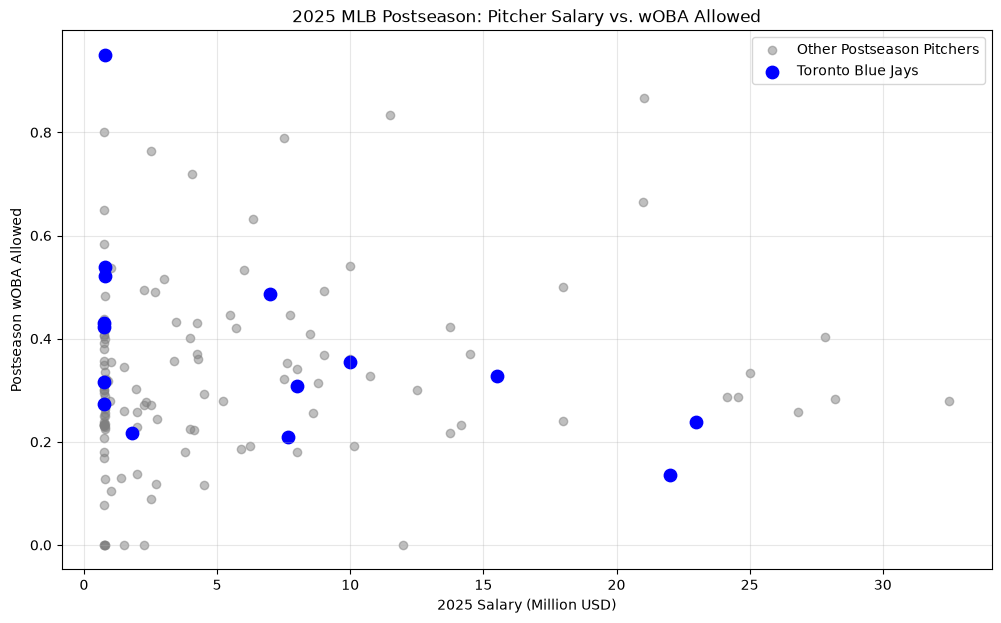

In [37]:
import matplotlib.pyplot as plt

# Convert salary to millions for easier visualization
pitcher_salary["salary_million"] = (
    pitcher_salary["salary_usd"] / 1_000_000
)

# Separate Blue Jays pitchers from other teams
tor_pitchers = pitcher_salary[
    pitcher_salary["pitching_team"] == "TOR"
]

other_pitchers = pitcher_salary[
    pitcher_salary["pitching_team"] != "TOR"
]

plt.figure(figsize=(12, 7))

# Other postseason pitchers
plt.scatter(
    other_pitchers["salary_million"],
    other_pitchers["woba_allowed"],
    color="gray",
    alpha=0.5,
    label="Other Postseason Pitchers"
)

# Blue Jays pitchers
plt.scatter(
    tor_pitchers["salary_million"],
    tor_pitchers["woba_allowed"],
    color="blue",
    s=80,
    label="Toronto Blue Jays"
)

plt.xlabel("2025 Salary (Million USD)")
plt.ylabel("Postseason wOBA Allowed")
plt.title("2025 MLB Postseason: Pitcher Salary vs. wOBA Allowed")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [38]:
tor_pitchers[[
    "full_name",
    "salary_usd",
    "woba_allowed",
    "total_pa_faced"
]].sort_values("salary_usd", ascending=False)

,full_name,salary_usd,woba_allowed,total_pa_faced
14,Kevin Gausman,23000000.0,0.239224,116.0
25,Chris Bassitt,22000000.0,0.136667,30.0
0,Max Scherzer,15500000.0,0.327586,58.0
82,Shane Bieber,10000000.0,0.354268,82.0
40,Seranthony Domínguez,8000000.0,0.308163,49.0
55,Jeff Hoffman,7666667.0,0.209783,46.0
121,Yariel Rodríguez,7000000.0,0.485714,14.0
44,Eric Lauer,1797849.0,0.216667,33.0
104,Justin Bruihl,800000.0,0.950000,4.0
74,Tommy Nance,785000.0,0.538889,9.0


Big concern here, the wOBA that we have here could be greater or smaller due to the lower denominator (total_pa_faced). How can we normalize it. 

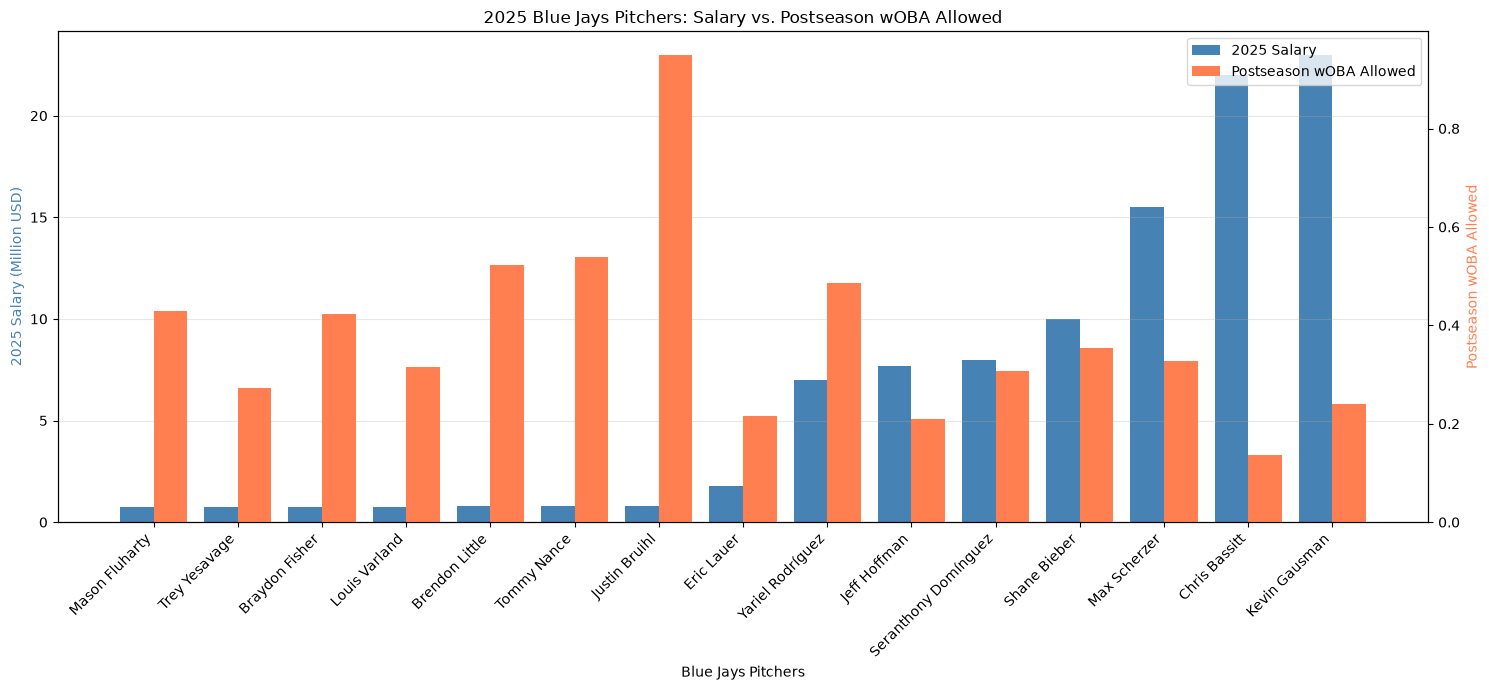

In [39]:
import matplotlib.pyplot as plt
import numpy as np

# Sort Blue Jays pitchers by salary
tor_plot = tor_pitchers.sort_values(
    "salary_usd", ascending=True
).copy()

x = np.arange(len(tor_plot))
width = 0.4

fig, ax1 = plt.subplots(figsize=(15, 7))
ax2 = ax1.twinx()

# Salary bars
bars1 = ax1.bar(
    x - width/2,
    tor_plot["salary_usd"] / 1_000_000,
    width,
    color="steelblue",
    label="2025 Salary"
)

# wOBA allowed bars
bars2 = ax2.bar(
    x + width/2,
    tor_plot["woba_allowed"],
    width,
    color="coral",
    label="Postseason wOBA Allowed"
)

# Labels
ax1.set_xlabel("Blue Jays Pitchers")
ax1.set_ylabel("2025 Salary (Million USD)", color="steelblue")
ax2.set_ylabel("Postseason wOBA Allowed", color="coral")

ax1.set_xticks(x)
ax1.set_xticklabels(
    tor_plot["full_name"],
    rotation=45,
    ha="right"
)

plt.title("2025 Blue Jays Pitchers: Salary vs. Postseason wOBA Allowed")

# Legend
ax1.legend(
    [bars1, bars2],
    ["2025 Salary", "Postseason wOBA Allowed"],
    loc="upper right"
)

ax1.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

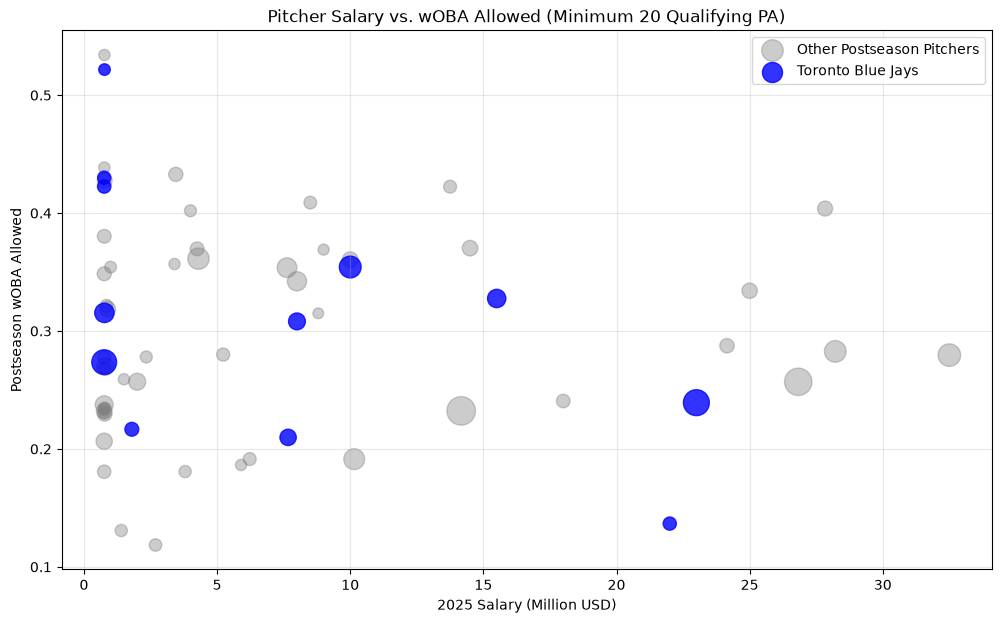

Pitchers included: 63
Pitchers excluded from this graph: 80


In [40]:
#pitchers with at least 20 qualifying pa faced
qualified = pitcher_salary[
    pitcher_salary["total_pa_faced"] >= 20
].copy()

tor = qualified[qualified["pitching_team"] == "TOR"]
others = qualified[qualified["pitching_team"] != "TOR"]

plt.figure(figsize=(12, 7))

plt.scatter(
    others["salary_million"],
    others["woba_allowed"],
    s=others["total_pa_faced"] * 3,
    color="gray",
    alpha=0.4,
    label="Other Postseason Pitchers"
)

plt.scatter(
    tor["salary_million"],
    tor["woba_allowed"],
    s=tor["total_pa_faced"] * 3,
    color="blue",
    alpha=0.8,
    label="Toronto Blue Jays"
)

plt.xlabel("2025 Salary (Million USD)")
plt.ylabel("Postseason wOBA Allowed")
plt.title("Pitcher Salary vs. wOBA Allowed (Minimum 20 Qualifying PA)")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Pitchers included:", len(qualified))
print("Pitchers excluded from this graph:",
      len(pitcher_salary) - len(qualified))

The bigger the dots are, the more times they are tried.

From visually looking at this scatter plot, there may be a downward regression trend that can be drawn on higher the salary, lower the wOBA allowed. 

But safer end, it is to say that higher the salary, the more stablized the wOBA allowed becomes

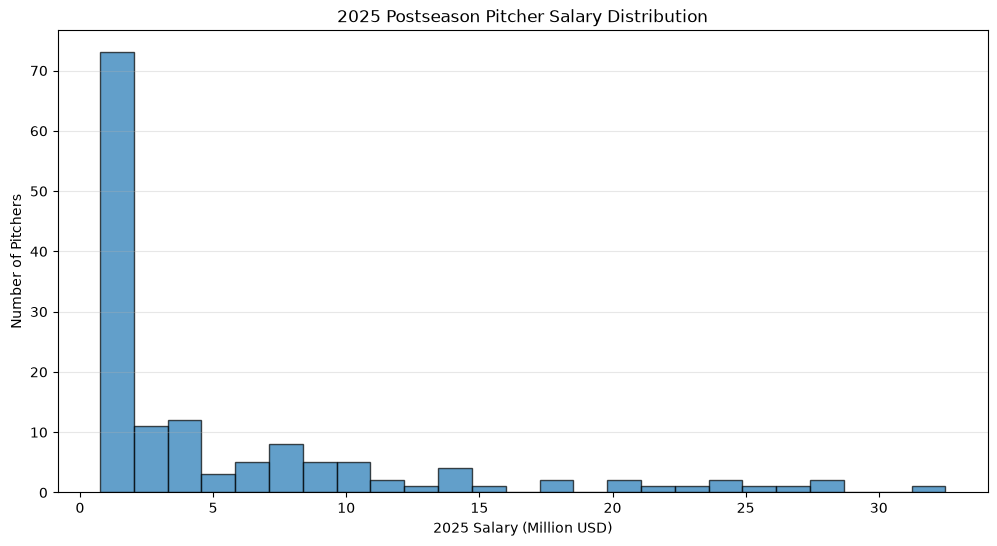

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.hist(
    pitcher_salary["salary_million"],
    bins=25,
    edgecolor="black",
    alpha=0.7
)

plt.xlabel("2025 Salary (Million USD)")
plt.ylabel("Number of Pitchers")
plt.title("2025 Postseason Pitcher Salary Distribution")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [42]:
pitcher_salary["salary_usd"].describe()

count    1.430000e+02
mean     5.363098e+06
std      7.052995e+06
min      7.483740e+05
25%      7.724000e+05
50%      2.000000e+06
75%      7.645834e+06
max      3.250000e+07
Name: salary_usd, dtype: float64

In [43]:
print(
    "Pitchers earning $1M or less:",
    (pitcher_salary["salary_usd"] <= 1_000_000).sum()
)

print(
    "Pitchers earning over $20M:",
    (pitcher_salary["salary_usd"] > 20_000_000).sum()
)

Pitchers earning $1M or less: 64
Pitchers earning over $20M: 11


In [44]:
pitcher_salary["salary_group"] = pd.qcut(
    pitcher_salary["salary_usd"],
    q=4,
    duplicates="drop"
)

pitcher_salary.groupby(
    "salary_group",
    observed=True
).agg(
    pitchers=("pitcher", "count"),
    min_salary=("salary_usd", "min"),
    max_salary=("salary_usd", "max"),
    median_woba=("woba_allowed", "median")
)

,pitchers,min_salary,max_salary,median_woba
salary_group,,,,
"(748373.999, 772400.0]",36,748374.0,771800.0,0.300000
"(772400.0, 2000000.0]",37,773000.0,2000000.0,0.277778
"(2000000.0, 7645833.5]",34,2250000.0,7625000.0,0.355275
"(7645833.5, 32500000.0]",36,7666667.0,32500000.0,0.321136


The distribution is strongly right-skewed. Many pitchers earn around the MLB minimum, while a smaller number earn substantially more.
Higher salary doesn't consistently correspond to lower wOBA allowed. Q2 actually has the lowest median of the four groups.
The salary ranges are very uneven. Q1 covers only about 24000,  whereas Q4 covers almost 25 million.


In [45]:
qualified = pitcher_salary[
    pitcher_salary["total_pa_faced"] >= 20
].copy()

qualified["salary_group"] = pd.qcut(
    qualified["salary_usd"],
    q=4,
    duplicates="drop"
)

qualified.groupby("salary_group", observed=True).agg(
    pitchers=("pitcher", "count"),
    min_salary=("salary_usd", "min"),
    max_salary=("salary_usd", "max"),
    median_woba=("woba_allowed", "median")
)

,pitchers,min_salary,max_salary,median_woba
salary_group,,,,
"(748373.999, 769975.0]",16,748374.0,768150.0,0.275586
"(769975.0, 3400000.0]",16,771800.0,3400000.0,0.269281
"(3400000.0, 9500000.0]",15,3450000.0,9000000.0,0.342187
"(9500000.0, 32500000.0]",16,10000000.0,32500000.0,0.285108


Recalculate with only 20 tries or more since less would be too small of a sample for our benchmark

In [46]:
# Calculate median wOBA allowed for each salary group
qualified["benchmark_woba"] = (
    qualified.groupby("salary_group", observed=True)["woba_allowed"]
    .transform("median")
)

# Compare each pitcher against their salary group's benchmark
qualified["salary_adjusted_score"] = (
    qualified["woba_allowed"] - qualified["benchmark_woba"]
)

In [47]:
tor_benchmark = qualified[
    qualified["pitching_team"] == "TOR"
].copy()

tor_benchmark[[
    "full_name",
    "salary_usd",
    "total_pa_faced",
    "woba_allowed",
    "benchmark_woba",
    "salary_adjusted_score"
]].sort_values("salary_adjusted_score")

,full_name,salary_usd,total_pa_faced,woba_allowed,benchmark_woba,salary_adjusted_score
25,Chris Bassitt,22000000.0,30.0,0.136667,0.285108,-0.148441
55,Jeff Hoffman,7666667.0,46.0,0.209783,0.342187,-0.132405
44,Eric Lauer,1797849.0,33.0,0.216667,0.269281,-0.052614
14,Kevin Gausman,23000000.0,116.0,0.239224,0.285108,-0.045884
40,Seranthony Domínguez,8000000.0,49.0,0.308163,0.342187,-0.034024
138,Trey Yesavage,760000.0,106.0,0.273585,0.275586,-0.002001
124,Louis Varland,768150.0,65.0,0.315385,0.275586,0.039799
0,Max Scherzer,15500000.0,58.0,0.327586,0.285108,0.042478
82,Shane Bieber,10000000.0,82.0,0.354268,0.285108,0.069160
108,Braydon Fisher,760000.0,31.0,0.422581,0.275586,0.146995


6 pitchers negative - meaning they performed well against their salary group-medians
6 pitchers postive - meaning performed worse

Bassitt and Hoffman performed particularly well 
Little performed particularly worse

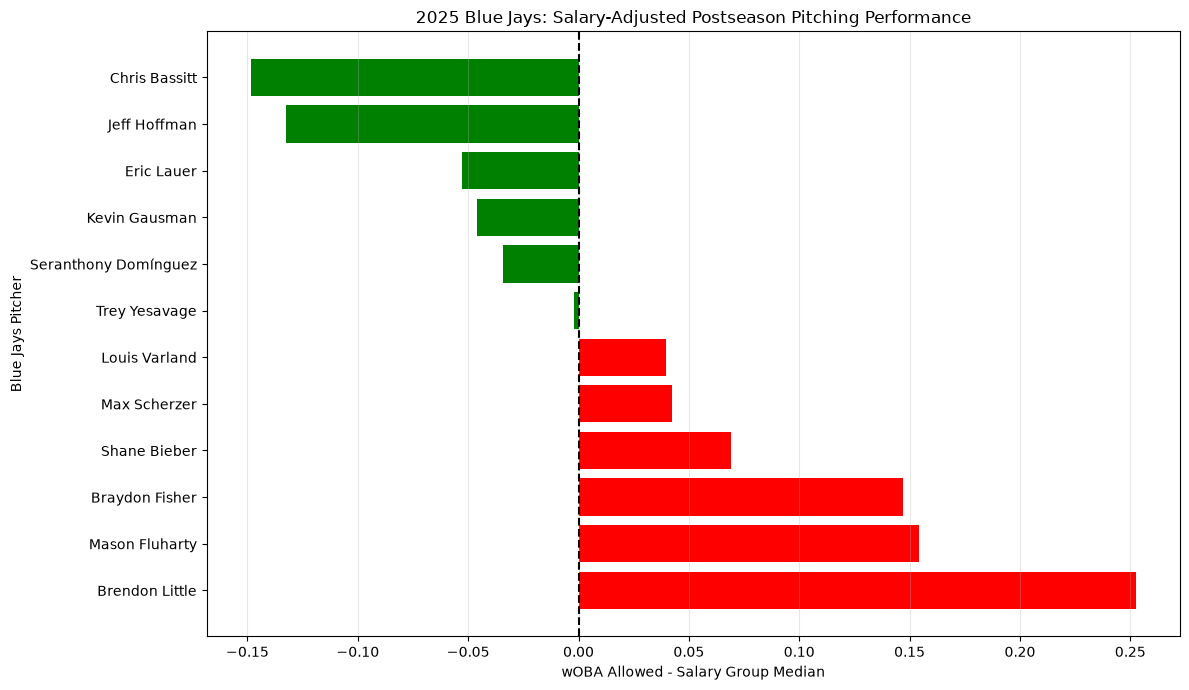

In [48]:
import matplotlib.pyplot as plt


tor_plot = tor_benchmark.sort_values(
    "salary_adjusted_score",
    ascending=False
)


colors = [
    "green" if score < 0 else "red"
    for score in tor_plot["salary_adjusted_score"]
]

plt.figure(figsize=(12, 7))

plt.barh(
    tor_plot["full_name"],
    tor_plot["salary_adjusted_score"],
    color=colors
)

plt.axvline(0, color="black", linestyle="--")

plt.xlabel("wOBA Allowed - Salary Group Median")
plt.ylabel("Blue Jays Pitcher")
plt.title("2025 Blue Jays: Salary-Adjusted Postseason Pitching Performance")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Benchmark version 2 - nearest salary peers

In [49]:
qualified_v2 = pitcher_salary[
    pitcher_salary["total_pa_faced"] >= 20
].copy()

def find_salary_peers(player, n=10):

    #exclude the player himself
    peers = qualified_v2[
    (qualified_v2["pitching_team"] != "TOR")
    & (qualified_v2["pitcher"] != player["pitcher"])
        ].copy()

    #calculate absolute salary differences
    peers["salary_difference"] = abs(
        peers["salary_usd"] - player["salary_usd"]
    )

    # Select the 10 closest salaries
    peers = peers.sort_values(
        ["salary_difference", "pitcher"]
    ).head(n)

    return peers

In [50]:
# Select Blue Jays pitchers
tor_v2 = qualified_v2[
    qualified_v2["pitching_team"] == "TOR"
].copy()

# Calculate each player's nearest-salary benchmark
tor_v2["benchmark_v2"] = tor_v2.apply(
    lambda player: find_salary_peers(player)["woba_allowed"].median(),
    axis=1
)

# Calculate the salary-adjusted score
tor_v2["score_v2"] = (
    tor_v2["woba_allowed"] - tor_v2["benchmark_v2"]
)

In [51]:
tor_v2[[
    "full_name",
    "salary_usd",
    "total_pa_faced",
    "woba_allowed",
    "benchmark_v2",
    "score_v2"
]].sort_values("score_v2")

,full_name,salary_usd,total_pa_faced,woba_allowed,benchmark_v2,score_v2
25,Chris Bassitt,22000000.0,30.0,0.136667,0.285108,-0.148441
55,Jeff Hoffman,7666667.0,46.0,0.209783,0.328594,-0.118811
44,Eric Lauer,1797849.0,33.0,0.216667,0.269281,-0.052614
14,Kevin Gausman,23000000.0,116.0,0.239224,0.285108,-0.045884
0,Max Scherzer,15500000.0,58.0,0.327586,0.351326,-0.023740
40,Seranthony Domínguez,8000000.0,49.0,0.308163,0.328594,-0.020430
82,Shane Bieber,10000000.0,82.0,0.354268,0.347959,0.006309
138,Trey Yesavage,760000.0,106.0,0.273585,0.235795,0.037789
124,Louis Varland,768150.0,65.0,0.315385,0.257543,0.057842
108,Braydon Fisher,760000.0,31.0,0.422581,0.235795,0.186785


Lets check a player and his nearest 10 neighbors 


In [52]:
# Select Chris Bassitt
bassitt = tor_v2[
    tor_v2["full_name"] == "Chris Bassitt"
].iloc[0]

# Find his 10 closest-salary peers
bassitt_peers = find_salary_peers(bassitt)

bassitt_peers[[
    "full_name",
    "pitching_team",
    "salary_usd",
    "salary_difference",
    "woba_allowed",
    "total_pa_faced"
]]

,full_name,pitching_team,salary_usd,salary_difference,woba_allowed,total_pa_faced
39,Luis Castillo,SEA,24150000.0,2150000.0,0.287500,36.0
54,Jack Flaherty,DET,25000000.0,3000000.0,0.334146,41.0
17,Jameson Taillon,CHC,18000000.0,4000000.0,0.240625,32.0
27,Blake Snell,LAD,26825953.0,4825953.0,0.256923,130.0
30,Carlos Rodón,NYY,27833333.0,5833333.0,0.403846,39.0
60,Shohei Ohtani,LAD,28216944.0,6216944.0,0.282716,81.0
34,Max Fried,NYY,14500000.0,7500000.0,0.370238,42.0
141,Yoshinobu Yamamoto,LAD,14166667.0,7833333.0,0.232270,141.0
120,Shota Imanaga,CHC,13750000.0,8250000.0,0.422414,29.0
31,Tyler Glasnow,LAD,32500000.0,10500000.0,0.279545,88.0


It checks out. Now that we have V2 benchmark analysis, lets compare V1 and V2 benchmarks and see if the V1 results hold against V2 results 

In [53]:
v1_scores = tor_benchmark[[
    "pitcher",
    "salary_adjusted_score"
]].rename(
    columns={"salary_adjusted_score": "score_v1"}
)

comparison = tor_v2.merge(
    v1_scores,
    on="pitcher",
    how="left"
)

comparison[[
    "full_name",
    "salary_usd",
    "woba_allowed",
    "score_v1",
    "score_v2"
]].sort_values("score_v2")

,full_name,salary_usd,woba_allowed,score_v1,score_v2
2,Chris Bassitt,22000000.0,0.136667,-0.148441,-0.148441
5,Jeff Hoffman,7666667.0,0.209783,-0.132405,-0.118811
4,Eric Lauer,1797849.0,0.216667,-0.052614,-0.052614
1,Kevin Gausman,23000000.0,0.239224,-0.045884,-0.045884
0,Max Scherzer,15500000.0,0.327586,0.042478,-0.023740
3,Seranthony Domínguez,8000000.0,0.308163,-0.034024,-0.020430
7,Shane Bieber,10000000.0,0.354268,0.069160,0.006309
11,Trey Yesavage,760000.0,0.273585,-0.002001,0.037789
9,Louis Varland,768150.0,0.315385,0.039799,0.057842
8,Braydon Fisher,760000.0,0.422581,0.146995,0.186785


Now that we have V1 and V2, and they seem to be closely together. We should also consider the earlier issue, the denominators. 

In V1 and V2, we assume that each player in the quantile (V1) or each closest peer (V2), their wOBA have equal influence regardless of the "tries" or plate appeareances. We should normalize it. 

Idea for V3 benchmark would be PA weighted nearest-salary benchmark 

In [54]:
# V3: PA-weighted nearest-salary benchmark

def weighted_peer_benchmark(player):
    peers = find_salary_peers(player, n=10)

    weighted_woba = (
        (peers["woba_allowed"] * peers["total_pa_faced"]).sum()
        / peers["total_pa_faced"].sum()
    )

    return weighted_woba

tor_v3 = tor_v2.copy()

tor_v3["benchmark_v3"] = tor_v3.apply(
    weighted_peer_benchmark,
    axis=1
)

tor_v3["score_v3"] = (
    tor_v3["woba_allowed"] - tor_v3["benchmark_v3"]
)

tor_v3[[
    "full_name",
    "salary_usd",
    "total_pa_faced",
    "woba_allowed",
    "benchmark_v3",
    "score_v3"
]].sort_values("score_v3")

,full_name,salary_usd,total_pa_faced,woba_allowed,benchmark_v3,score_v3
25,Chris Bassitt,22000000.0,30.0,0.136667,0.286722,-0.150056
55,Jeff Hoffman,7666667.0,46.0,0.209783,0.298246,-0.088463
14,Kevin Gausman,23000000.0,116.0,0.239224,0.286722,-0.047498
44,Eric Lauer,1797849.0,33.0,0.216667,0.261025,-0.044358
138,Trey Yesavage,760000.0,106.0,0.273585,0.268657,0.004928
40,Seranthony Domínguez,8000000.0,49.0,0.308163,0.298246,0.009918
124,Louis Varland,768150.0,65.0,0.315385,0.300339,0.015046
0,Max Scherzer,15500000.0,58.0,0.327586,0.293939,0.033647
82,Shane Bieber,10000000.0,82.0,0.354268,0.308668,0.045600
108,Braydon Fisher,760000.0,31.0,0.422581,0.268657,0.153924


This completes the third salary benchmark. It gives greater influence to peers with more qualifying opportunities, although it does not eliminate small-sample uncertainty

Workload comparisons

How did Blue Jays pitchers perform compared with teammates who faced similar numbers of batters during the 2025 postseason?

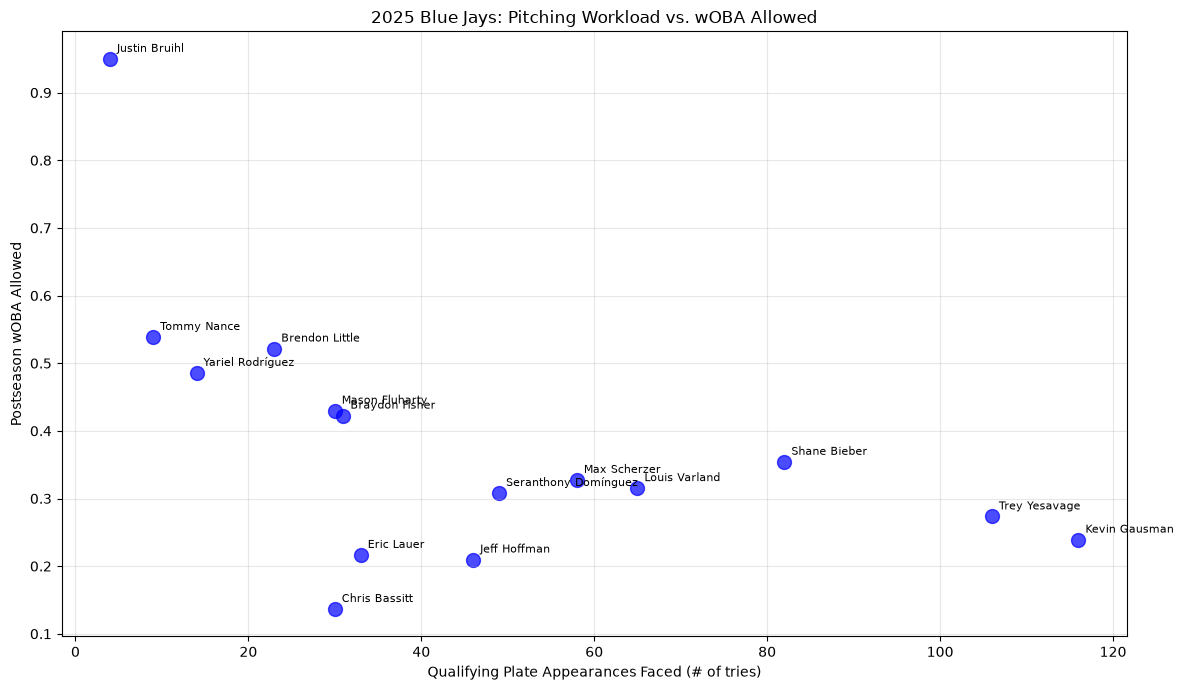

In [55]:
import matplotlib.pyplot as plt

# Select Blue Jays pitchers
tor_workload = pitcher_salary[
    pitcher_salary["pitching_team"] == "TOR"
].copy()

plt.figure(figsize=(12, 7))

plt.scatter(
    tor_workload["total_pa_faced"],
    tor_workload["woba_allowed"],
    s=100,
    color="blue",
    alpha=0.7
)

# Label each pitcher
for _, player in tor_workload.iterrows():
    plt.annotate(
        player["full_name"],
        (player["total_pa_faced"], player["woba_allowed"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Qualifying Plate Appearances Faced (# of tries)")
plt.ylabel("Postseason wOBA Allowed")
plt.title("2025 Blue Jays: Pitching Workload vs. wOBA Allowed")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [56]:
tor_workload[[
    "full_name",
    "total_pa_faced",
    "woba_allowed",
    "salary_usd"
]].sort_values("total_pa_faced")

,full_name,total_pa_faced,woba_allowed,salary_usd
104,Justin Bruihl,4.0,0.950000,800000.0
74,Tommy Nance,9.0,0.538889,785000.0
121,Yariel Rodríguez,14.0,0.485714,7000000.0
68,Brendon Little,23.0,0.521739,771800.0
25,Chris Bassitt,30.0,0.136667,22000000.0
128,Mason Fluharty,30.0,0.430000,760000.0
108,Braydon Fisher,31.0,0.422581,760000.0
44,Eric Lauer,33.0,0.216667,1797849.0
55,Jeff Hoffman,46.0,0.209783,7666667.0
40,Seranthony Domínguez,49.0,0.308163,8000000.0


Bassitt, Fluharty and Fisher all faced approximately 30 qualifying plate appearances, yet their wOBA allowed differs.

However, similar workloads don't guarantee identical circumstances. Pitchers may have different roles, opponents and pitching situations.

In [57]:
from itertools import combinations

# Keep Blue Jays pitchers with at least 20 qualifying PA
tor_qualified = tor_workload[
    tor_workload["total_pa_faced"] >= 20
].copy()

pairs = []

# Compare each possible pair of pitchers
for (_, a), (_, b) in combinations(tor_qualified.iterrows(), 2):

    pa_diff = abs(a["total_pa_faced"] - b["total_pa_faced"])

    if pa_diff <= 10:
        pairs.append({
            "Pitcher A": a["full_name"],
            "Pitcher B": b["full_name"],
            "PA A": a["total_pa_faced"],
            "PA B": b["total_pa_faced"],
            "PA Difference": pa_diff,
            "wOBA A": a["woba_allowed"],
            "wOBA B": b["woba_allowed"],
            "Salary A": a["salary_usd"],
            "Salary B": b["salary_usd"]
        })

workload_pairs = pd.DataFrame(pairs)

workload_pairs.sort_values("PA Difference")

,Pitcher A,Pitcher B,PA A,PA B,PA Difference,wOBA A,wOBA B,Salary A,Salary B
6,Chris Bassitt,Mason Fluharty,30.0,30.0,0.0,0.136667,0.430000,22000000.0,760000.0
5,Chris Bassitt,Braydon Fisher,30.0,31.0,1.0,0.136667,0.422581,22000000.0,760000.0
13,Braydon Fisher,Mason Fluharty,31.0,30.0,1.0,0.422581,0.430000,760000.0,760000.0
9,Eric Lauer,Braydon Fisher,33.0,31.0,2.0,0.216667,0.422581,1797849.0,760000.0
3,Chris Bassitt,Eric Lauer,30.0,33.0,3.0,0.136667,0.216667,22000000.0,1797849.0
10,Eric Lauer,Mason Fluharty,33.0,30.0,3.0,0.216667,0.430000,1797849.0,760000.0
7,Seranthony Domínguez,Jeff Hoffman,49.0,46.0,3.0,0.308163,0.209783,8000000.0,7666667.0
1,Max Scherzer,Louis Varland,58.0,65.0,7.0,0.327586,0.315385,15500000.0,768150.0
4,Chris Bassitt,Brendon Little,30.0,23.0,7.0,0.136667,0.521739,22000000.0,771800.0
12,Brendon Little,Mason Fluharty,23.0,30.0,7.0,0.521739,0.430000,771800.0,760000.0


visualize workload, performance and salary together

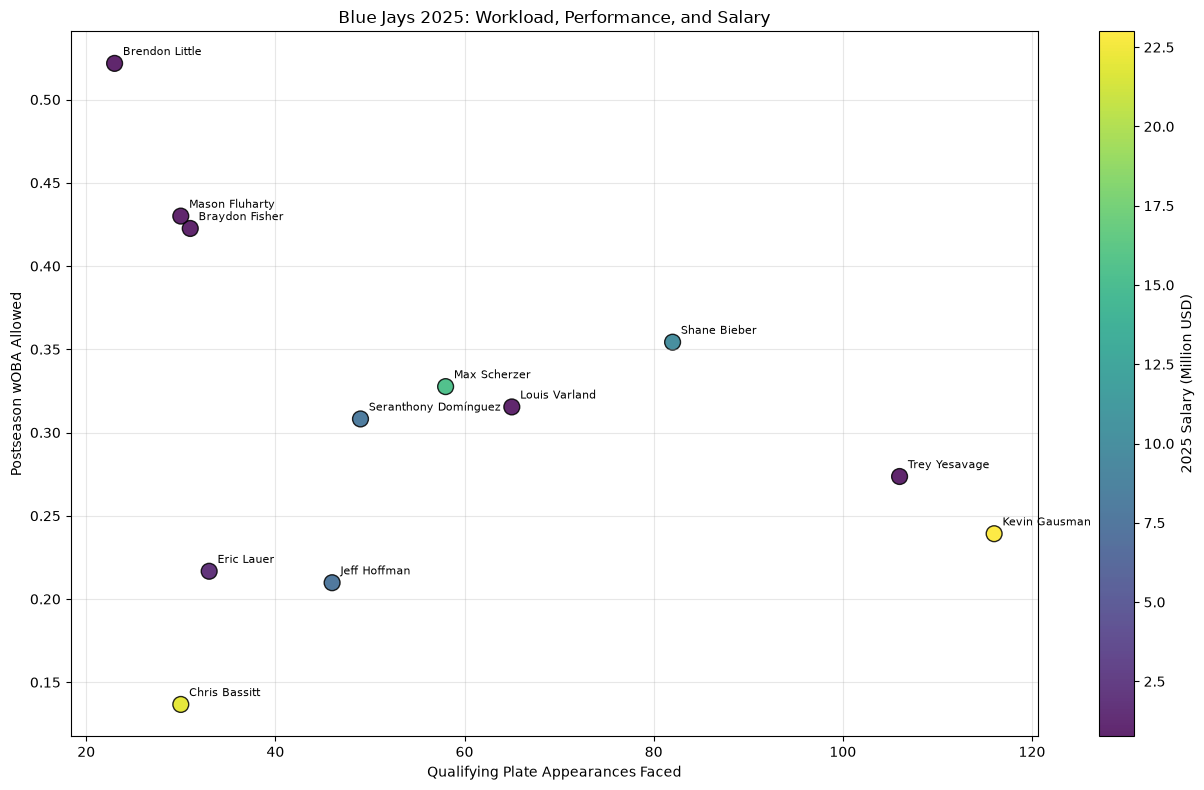

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 8))

scatter = plt.scatter(
    tor_qualified["total_pa_faced"],
    tor_qualified["woba_allowed"],
    c=tor_qualified["salary_usd"] / 1_000_000,
    cmap="viridis",
    s=130,
    alpha=0.85,
    edgecolors="black"
)

# Add player names
for _, player in tor_qualified.iterrows():
    plt.annotate(
        player["full_name"],
        (player["total_pa_faced"], player["woba_allowed"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8
    )

plt.colorbar(scatter, label="2025 Salary (Million USD)")

plt.xlabel("Qualifying Plate Appearances Faced")
plt.ylabel("Postseason wOBA Allowed")
plt.title("Blue Jays 2025: Workload, Performance, and Salary")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Now we can see pitchers with similar workloads but different performance outcomes, while also seeing how much they're paid.

Pitchers with comparable postseason workloads can have substantially different wOBA allowed, and salary does not necessarily explain those differences.

RQ2's (workload comparison) initial exploratory analysis complete.

Now we begin RQ3: Series-Level Pitching Performance

In [59]:
# Keep games involving Toronto
tor_games = df[
    (df["home_team"] == "TOR") |
    (df["away_team"] == "TOR")
].copy()

# Identify playoff series
series_names = {
    "D": "ALDS vs Yankees",
    "L": "ALCS vs Mariners",
    "W": "World Series vs Dodgers"
}

tor_games["series"] = tor_games["game_type"].map(series_names)

# Identify which team is pitching
tor_games["pitching_team"] = tor_games["home_team"].where(
    tor_games["inning_topbot"] == "Top",
    tor_games["away_team"]
)

# Verify games in each series
tor_games[["game_pk", "series"]].drop_duplicates().groupby("series").size()

series
ALCS vs Mariners           7
ALDS vs Yankees            4
World Series vs Dodgers    7
dtype: int64

Grouping by series

In [60]:
# Keep qualifying wOBA outcomes
series_pa = tor_games[
    tor_games["woba_denom"] == 1
].copy()

# Calculate pitcher performance by series
pitcher_series = series_pa.groupby(
    ["series", "pitching_team", "pitcher", "player_name"]
).agg(
    total_woba_value=("woba_value", "sum"),
    total_pa_faced=("woba_denom", "sum"),
    games_played=("game_pk", "nunique")
).reset_index()

pitcher_series["woba_allowed"] = (
    pitcher_series["total_woba_value"] /
    pitcher_series["total_pa_faced"]
)

# Add salaries from our existing dataset
pitcher_series = pitcher_series.merge(
    pitcher_salary[["pitcher", "salary_usd"]].drop_duplicates(),
    on="pitcher",
    how="left",
    validate="many_to_one"
)

pitcher_series.head(10)

,series,pitching_team,pitcher,player_name,total_woba_value,total_pa_faced,games_played,woba_allowed,salary_usd
0,ALCS vs Mariners,SEA,592426,"Jackson, Luke",4.15,9.0,1,0.461111,1500000.0
1,ALCS vs Mariners,SEA,622491,"Castillo, Luis",6.65,13.0,1,0.511538,24150000.0
2,ALCS vs Mariners,SEA,642100,"Speier, Gabe",2.85,12.0,3,0.237500,845000.0
3,ALCS vs Mariners,SEA,657571,"Ferguson, Caleb",3.80,9.0,1,0.422222,3000000.0
4,ALCS vs Mariners,SEA,660825,"Bazardo, Eduard",7.05,22.0,4,0.320455,892700.0
5,ALCS vs Mariners,SEA,662253,"Muñoz, Andrés",1.80,10.0,3,0.180000,2687500.0
6,ALCS vs Mariners,SEA,666374,"Brash, Matt",4.95,19.0,4,0.260526,777600.0
7,ALCS vs Mariners,SEA,669302,"Gilbert, Logan",16.35,36.0,2,0.454167,7625000.0
8,ALCS vs Mariners,SEA,669923,"Kirby, George",17.25,39.0,2,0.442308,4300000.0
9,ALCS vs Mariners,SEA,672841,"Vargas, Carlos",7.35,22.0,4,0.334091,761200.0


Calculate individual pitchers' wOBA allowed by series

In [61]:
team_series = series_pa.groupby(
    ["series", "pitching_team"]
).agg(
    total_woba_value=("woba_value", "sum"),
    total_pa_faced=("woba_denom", "sum")
).reset_index()

team_series["woba_allowed"] = (
    team_series["total_woba_value"] /
    team_series["total_pa_faced"]
)

team_series

,series,pitching_team,total_woba_value,total_pa_faced,woba_allowed
0,ALCS vs Mariners,SEA,93.90,263.0,0.357034
1,ALCS vs Mariners,TOR,83.15,255.0,0.326078
2,ALDS vs Yankees,NYY,65.40,159.0,0.411321
3,ALDS vs Yankees,TOR,50.65,153.0,0.331046
4,World Series vs Dodgers,LAD,104.00,312.0,0.333333
5,World Series vs Dodgers,TOR,80.95,288.0,0.281076


Looks like Toronto Blue jays performed better than the opponent in each series

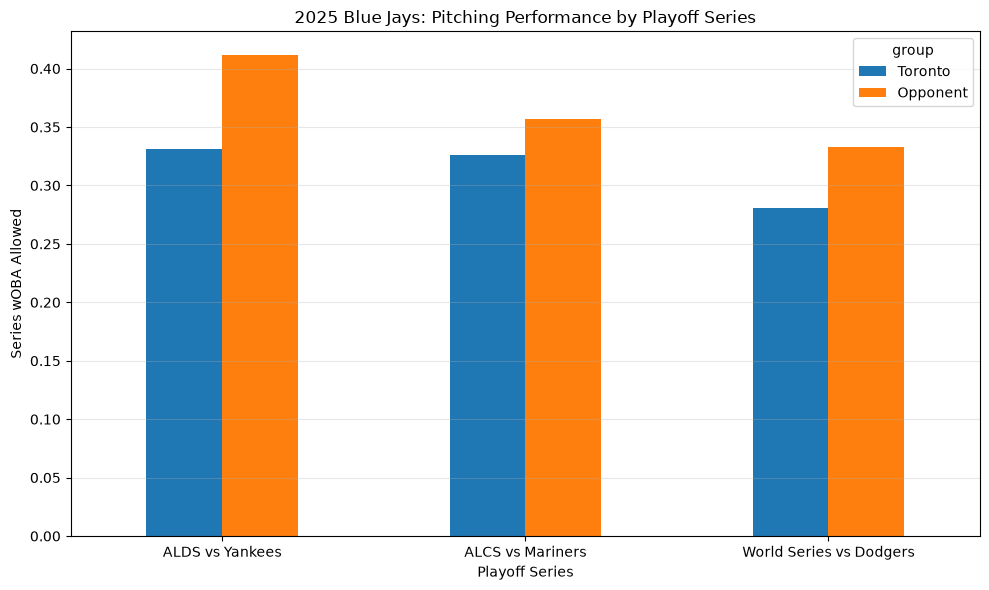

In [62]:
import matplotlib.pyplot as plt

team_series["group"] = team_series["pitching_team"].apply(
    lambda team: "Toronto" if team == "TOR" else "Opponent"
)

series_order = [
    "ALDS vs Yankees",
    "ALCS vs Mariners",
    "World Series vs Dodgers"
]

series_comparison = team_series.pivot(
    index="series",
    columns="group",
    values="woba_allowed"
).reindex(series_order)

series_comparison[["Toronto", "Opponent"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Series wOBA Allowed")
plt.xlabel("Playoff Series")
plt.title("2025 Blue Jays: Pitching Performance by Playoff Series")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Visualized with bar graph

In [63]:
# Select Blue Jays pitchers
tor_series_pitchers = pitcher_series[
    pitcher_series["pitching_team"] == "TOR"
].copy()

# Display individual performance by series
tor_series_pitchers[[
    "series",
    "player_name",
    "total_pa_faced",
    "woba_allowed",
    "salary_usd"
]].sort_values(
    ["series", "total_pa_faced"],
    ascending=[True, False]
)

,series,player_name,total_pa_faced,woba_allowed,salary_usd
14,ALCS vs Mariners,"Gausman, Kevin",48.0,0.253125,23000000.0
25,ALCS vs Mariners,"Yesavage, Trey",42.0,0.366667,760000.0
20,ALCS vs Mariners,"Bieber, Shane",40.0,0.363750,10000000.0
23,ALCS vs Mariners,"Varland, Louis",26.0,0.263462,768150.0
13,ALCS vs Mariners,"Scherzer, Max",22.0,0.300000,15500000.0
18,ALCS vs Mariners,"Hoffman, Jeff",17.0,0.094118,7666667.0
16,ALCS vs Mariners,"Domínguez, Seranthony",16.0,0.368750,8000000.0
24,ALCS vs Mariners,"Fluharty, Mason",11.0,0.454545,760000.0
15,ALCS vs Mariners,"Bassitt, Chris",8.0,0.000000,22000000.0
21,ALCS vs Mariners,"Fisher, Braydon",8.0,0.475000,760000.0


This is the stats that every blue jays pitcher performance in each series

In [64]:
# Get opposing team benchmark for each series
opponent_benchmark = team_series[
    team_series["pitching_team"] != "TOR"
][["series", "woba_allowed"]].rename(
    columns={"woba_allowed": "opponent_woba_allowed"}
)

# Attach benchmark to Toronto pitchers
tor_series_pitchers = tor_series_pitchers.merge(
    opponent_benchmark,
    on="series",
    how="left",
    validate="many_to_one"
)

# Calculate difference
tor_series_pitchers["series_score"] = (
    tor_series_pitchers["woba_allowed"]
    - tor_series_pitchers["opponent_woba_allowed"]
)


tor_series_pitchers[[
    "series",
    "player_name",
    "total_pa_faced",
    "woba_allowed",
    "opponent_woba_allowed",
    "series_score"
]].sort_values(["series", "series_score"])

,series,player_name,total_pa_faced,woba_allowed,opponent_woba_allowed,series_score
2,ALCS vs Mariners,"Bassitt, Chris",8.0,0.000000,0.357034,-0.357034
5,ALCS vs Mariners,"Hoffman, Jeff",17.0,0.094118,0.357034,-0.262917
4,ALCS vs Mariners,"Lauer, Eric",4.0,0.225000,0.357034,-0.132034
1,ALCS vs Mariners,"Gausman, Kevin",48.0,0.253125,0.357034,-0.103909
10,ALCS vs Mariners,"Varland, Louis",26.0,0.263462,0.357034,-0.093573
0,ALCS vs Mariners,"Scherzer, Max",22.0,0.300000,0.357034,-0.057034
7,ALCS vs Mariners,"Bieber, Shane",40.0,0.363750,0.357034,0.006716
12,ALCS vs Mariners,"Yesavage, Trey",42.0,0.366667,0.357034,0.009632
3,ALCS vs Mariners,"Domínguez, Seranthony",16.0,0.368750,0.357034,0.011716
11,ALCS vs Mariners,"Fluharty, Mason",11.0,0.454545,0.357034,0.097511


We compared individual blue jays pitchers' "wOBA allowed" against the opposing team's pitching staff's combined "wOBA allowed" in every series and assigned a series score, a negative series_score means the Toronto pitcher allowed a lower wOBA than the opposing pitching staff, not necessarily that he was objectively the better pitcher

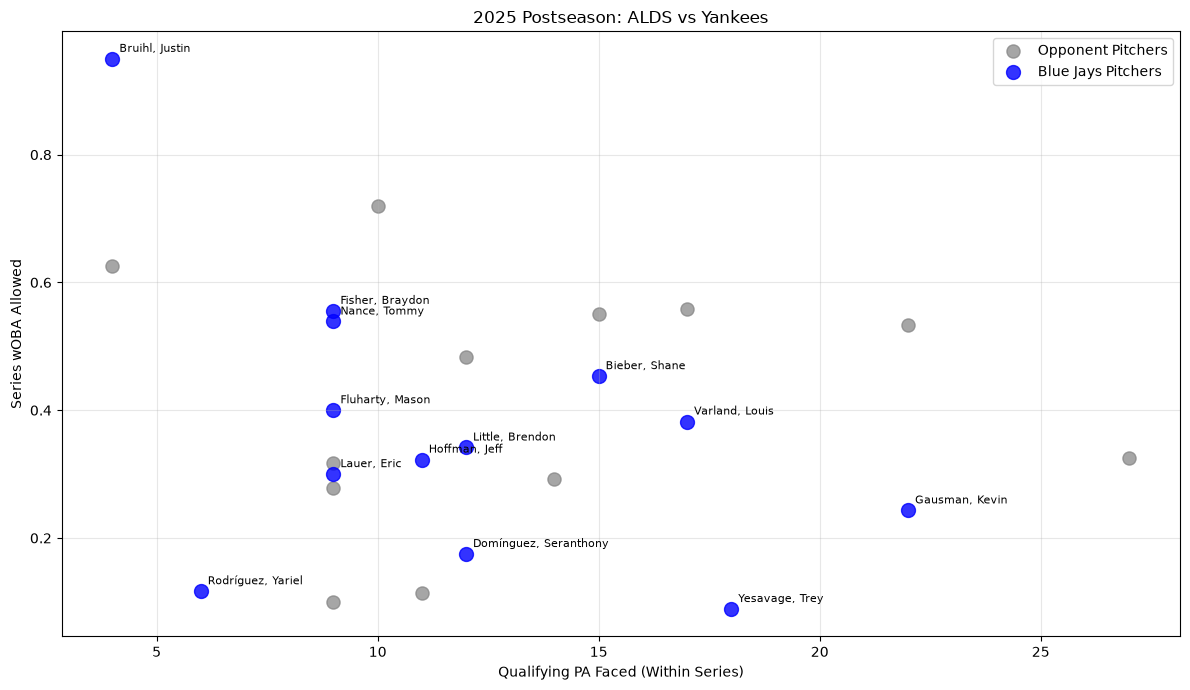

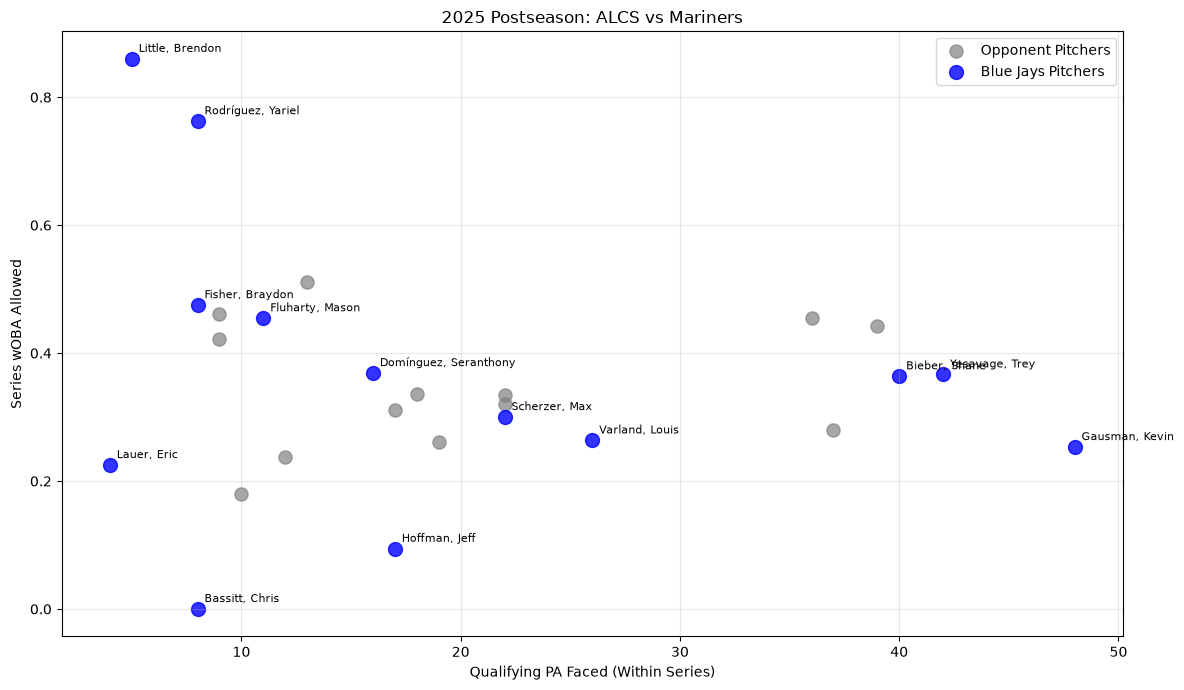

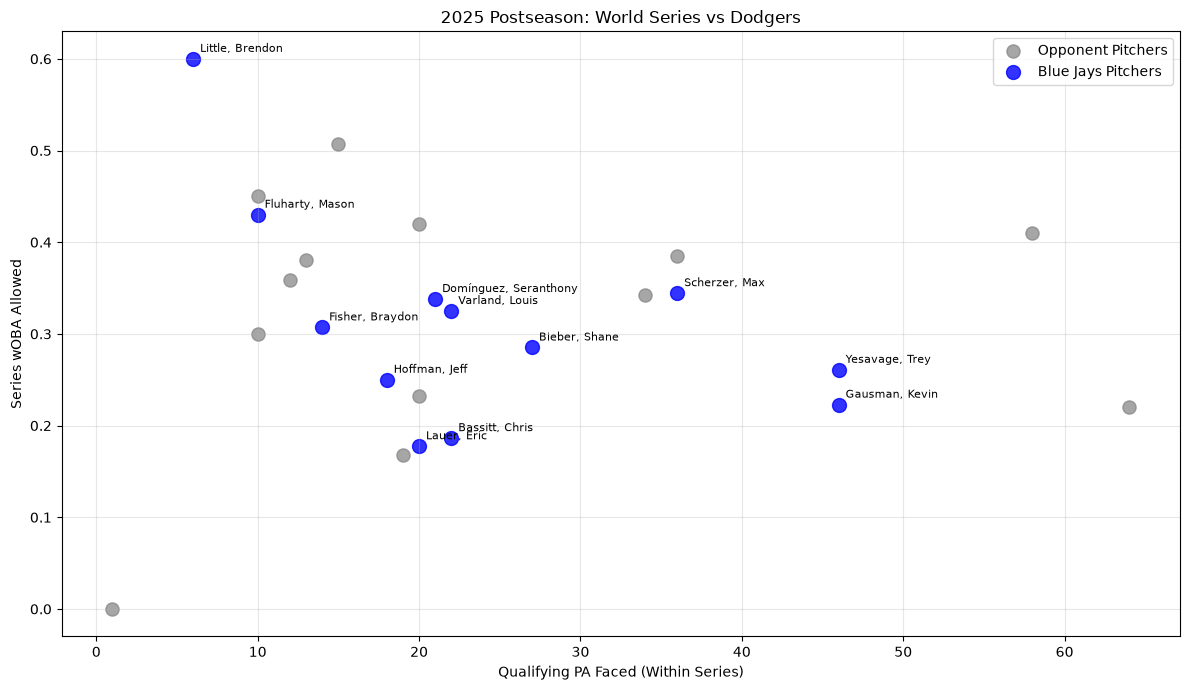

In [65]:
import matplotlib.pyplot as plt

series_order = [
    "ALDS vs Yankees",
    "ALCS vs Mariners",
    "World Series vs Dodgers"
]

for series in series_order:

    # Select pitchers who played in this series
    series_data = pitcher_series[
        pitcher_series["series"] == series
    ]

    # Separate Toronto and opponent pitchers
    tor = series_data[
        series_data["pitching_team"] == "TOR"
    ]

    opponents = series_data[
        series_data["pitching_team"] != "TOR"
    ]

    plt.figure(figsize=(12, 7))

    # Opponent pitchers
    plt.scatter(
        opponents["total_pa_faced"],
        opponents["woba_allowed"],
        color="gray",
        s=90,
        alpha=0.7,
        label="Opponent Pitchers"
    )

    # Blue Jays pitchers
    plt.scatter(
        tor["total_pa_faced"],
        tor["woba_allowed"],
        color="blue",
        s=100,
        alpha=0.8,
        label="Blue Jays Pitchers"
    )

    # Label Toronto pitchers
    for _, player in tor.iterrows():
        plt.annotate(
            player["player_name"],
            (player["total_pa_faced"], player["woba_allowed"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    plt.xlabel("Qualifying PA Faced (Within Series)")
    plt.ylabel("Series wOBA Allowed")
    plt.title(f"2025 Postseason: {series}")

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Visualized individual pitchers by series (Blue dots - TOR), (Grey dots - Opposing team)

Now we identify TOR vs Opponent pitcher pairs with similar workloads within each series, just like we did for RQ2

We will have 2 conditionns, both pitchers must have: 
at least 10 qualifying plate appearances within that series and their workloads must differ by no more than 10 qualifying plate appearances

In [66]:
from itertools import product

series_pairs_list = []

for series in series_order:

    # Select pitchers from this series
    data = pitcher_series[
        (pitcher_series["series"] == series) &
        (pitcher_series["total_pa_faced"] >= 10)
    ]

    # Separate Toronto and opposing pitchers
    tor = data[data["pitching_team"] == "TOR"]
    opp = data[data["pitching_team"] != "TOR"]

    # Compare every Toronto pitcher with opposing pitchers
    for (_, a), (_, b) in product(tor.iterrows(), opp.iterrows()):

        pa_diff = abs(a["total_pa_faced"] - b["total_pa_faced"])

        if pa_diff <= 10:
            series_pairs_list.append({
                "Series": series,
                "TOR Pitcher": a["player_name"],
                "Opponent Pitcher": b["player_name"],
                "TOR PA": a["total_pa_faced"],
                "Opponent PA": b["total_pa_faced"],
                "PA Difference": pa_diff,
                "TOR wOBA Allowed": a["woba_allowed"],
                "Opponent wOBA Allowed": b["woba_allowed"],
                "wOBA Difference": (
                    a["woba_allowed"] - b["woba_allowed"]
                )
            })

series_pairs = pd.DataFrame(series_pairs_list)

series_pairs.head()

,Series,TOR Pitcher,Opponent Pitcher,TOR PA,Opponent PA,PA Difference,TOR wOBA Allowed,Opponent wOBA Allowed,wOBA Difference
0,ALDS vs Yankees,"Gausman, Kevin","Rodón, Carlos",22.0,15.0,7.0,0.243182,0.550000,-0.306818
1,ALDS vs Yankees,"Gausman, Kevin","Fried, Max",22.0,17.0,5.0,0.243182,0.558824,-0.315642
2,ALDS vs Yankees,"Gausman, Kevin","Gil, Luis",22.0,12.0,10.0,0.243182,0.483333,-0.240152
3,ALDS vs Yankees,"Gausman, Kevin","Doval, Camilo",22.0,14.0,8.0,0.243182,0.292857,-0.049675
4,ALDS vs Yankees,"Gausman, Kevin","Schlittler, Cam",22.0,27.0,5.0,0.243182,0.325926,-0.082744


We're comparing pitchers only within the same series. A Blue Jays pitcher from the ALDS will only be compared against opposing team which is Yankees pitchers.

In [67]:
series_pairs.sort_values(
    ["Series", "PA Difference"]
)

,Series,TOR Pitcher,Opponent Pitcher,TOR PA,Opponent PA,PA Difference,TOR wOBA Allowed,Opponent wOBA Allowed,wOBA Difference
51,ALCS vs Mariners,"Scherzer, Max","Bazardo, Eduard",22.0,22.0,0.0,0.300000,0.320455,-0.020455
53,ALCS vs Mariners,"Scherzer, Max","Vargas, Carlos",22.0,22.0,0.0,0.300000,0.334091,-0.034091
71,ALCS vs Mariners,"Hoffman, Jeff","Hancock, Emerson",17.0,17.0,0.0,0.094118,0.311765,-0.217647
63,ALCS vs Mariners,"Domínguez, Seranthony","Hancock, Emerson",16.0,17.0,1.0,0.368750,0.311765,0.056985
72,ALCS vs Mariners,"Hoffman, Jeff","Woo, Bryan",17.0,18.0,1.0,0.094118,0.336111,-0.241993
...,...,...,...,...,...,...,...,...,...
110,World Series vs Dodgers,"Lauer, Eric","Henriquez, Edgardo",20.0,10.0,10.0,0.177500,0.300000,-0.122500
136,World Series vs Dodgers,"Varland, Louis","Dreyer, Jack",22.0,12.0,10.0,0.325000,0.358333,-0.033333
144,World Series vs Dodgers,"Fluharty, Mason","Wrobleski, Justin",10.0,20.0,10.0,0.430000,0.232500,0.197500
146,World Series vs Dodgers,"Fluharty, Mason","Sheehan, Emmet",10.0,20.0,10.0,0.430000,0.420000,0.010000


In [68]:
series_pairs.groupby("Series").agg(
    comparisons=("TOR Pitcher", "count"),
    tor_pitchers=("TOR Pitcher", "nunique"),
    opponent_pitchers=("Opponent Pitcher", "nunique")
)

,comparisons,tor_pitchers,opponent_pitchers
Series,,,
ALCS vs Mariners,42,8,11
ALDS vs Yankees,49,7,8
World Series vs Dodgers,59,11,10


Final Statistical Analysis and Validation

We will like at RQ1, Is there a statistically significant relationship between a pitcher's 2025 salary and postseason wOBA allowed?

We'll use Spearman's rank correlation because our salary distribution is heavily right-skewed, and we don't necessarily expect a linear relationship


Null hypothesis H0: There is no monotonic association between salary and postseason wOBA allowed. Alternative hypothesis H1: There is a monotonic association between salary and postseason wOBA allowed. Set signifcance level to Alpha = 0.05

In [69]:
from scipy.stats import spearmanr

# Use pitchers with at least 20 qualifying PA
rq1_data = pitcher_salary[
    pitcher_salary["total_pa_faced"] >= 20
].copy()

# Remove missing values, if any
rq1_data = rq1_data.dropna(
    subset=["salary_usd", "woba_allowed"]
)

# Spearman correlation test
rho, p_value = spearmanr(
    rq1_data["salary_usd"],
    rq1_data["woba_allowed"]
)

print("Number of pitchers:", len(rq1_data))
print("Spearman correlation:", round(rho, 4))
print("P-value:", round(p_value, 4))

Number of pitchers: 63
Spearman correlation: 0.0375
P-value: 0.7706


For this project, a negative correlation means higher-paid pitchers tend to allow lower wOBA, which is favorable pitching performance. A positive correlation means the opposite.

In [70]:
if p_value < 0.05:
    print("Statistically significant association (p < 0.05)")
else:
    print("No statistically significant association (p >= 0.05)")

No statistically significant association (p >= 0.05)


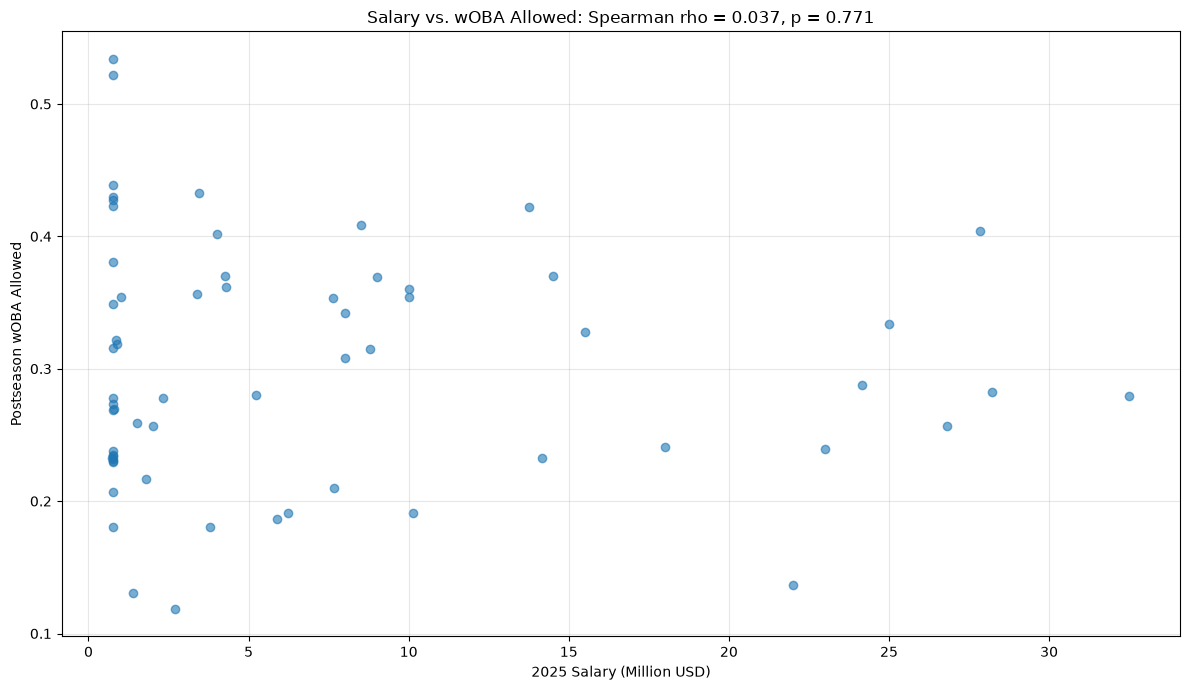

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.scatter(
    rq1_data["salary_usd"] / 1_000_000,
    rq1_data["woba_allowed"],
    alpha=0.6
)

plt.xlabel("2025 Salary (Million USD)")
plt.ylabel("Postseason wOBA Allowed")
plt.title(
    f"Salary vs. wOBA Allowed: Spearman rho = {rho:.3f}, p = {p_value:.3f}"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Results suggest that higher-paid pitchers did not consistently allow lower postseason wOBA in this particular sample.

However, we shouldn't conclude that salaries have no relationship with pitching ability generally. Our data includes only one postseason and excludes pitchers with fewer than 20 qualifying plate appearances.

Now we start statistical tests for RQ2 - workload based performance comparison. We will use bootstrapping to examine how uncertain the difference between two pitchers' wOBA allowed might be

In [72]:
import numpy as np
import matplotlib.pyplot as plt

# Gausman and Yesavage MLB IDs
gausman_id = 592332
yesavage_id = 702056

# Get qualifying PA outcomes for each pitcher
gausman_pa = df_woba.loc[
    df_woba["pitcher"] == gausman_id,
    "woba_value"
].dropna().to_numpy()

yesavage_pa = df_woba.loc[
    df_woba["pitcher"] == yesavage_id,
    "woba_value"
].dropna().to_numpy()

print("Gausman PA:", len(gausman_pa))
print("Yesavage PA:", len(yesavage_pa))

print("Gausman wOBA:", gausman_pa.mean())
print("Yesavage wOBA:", yesavage_pa.mean())

Gausman PA: 116
Yesavage PA: 106
Gausman wOBA: 0.2392241379310345
Yesavage wOBA: 0.27358490566037735


Gausman faced 116 qualifying plate appearances.

We randomly select 116 outcomes from those same 116 records, allowing some outcomes to be selected multiple times. We calculate the resulting wOBA, then repeat that process thousands of times.

We do the same for Yesavage.

By comparing the simulated wOBA values, we can estimate the uncertainty around their observed difference.

In [73]:
rng = np.random.default_rng(42)

n_bootstrap = 10000

# Resample qualifying plate appearances
gausman_boot = rng.choice(
    gausman_pa,
    size=(n_bootstrap, len(gausman_pa)),
    replace=True
).mean(axis=1)

yesavage_boot = rng.choice(
    yesavage_pa,
    size=(n_bootstrap, len(yesavage_pa)),
    replace=True
).mean(axis=1)

# Calculate the difference for each bootstrap sample
bootstrap_diff = gausman_boot - yesavage_boot

# Observed difference
observed_diff = gausman_pa.mean() - yesavage_pa.mean()

# 95% bootstrap confidence interval
ci_lower, ci_upper = np.percentile(
    bootstrap_diff, [2.5, 97.5]
)

print("Observed difference:", round(observed_diff, 4))
print("95% CI:", round(ci_lower, 4), "to", round(ci_upper, 4))

Observed difference: -0.0344
95% CI: -0.1691 to 0.0935


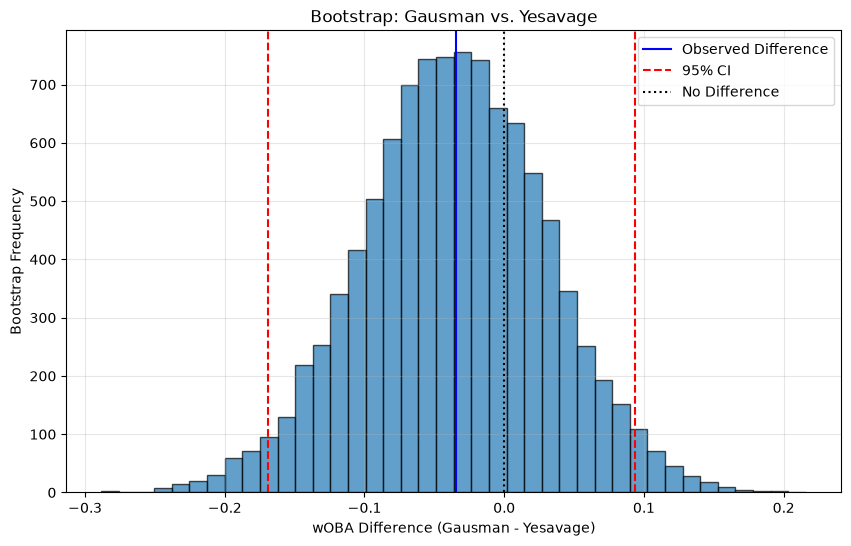

In [74]:
plt.figure(figsize=(10, 6))

plt.hist(
    bootstrap_diff,
    bins=40,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    observed_diff,
    color="blue",
    linestyle="-",
    label="Observed Difference"
)

plt.axvline(
    ci_lower,
    color="red",
    linestyle="--",
    label="95% CI"
)

plt.axvline(
    ci_upper,
    color="red",
    linestyle="--"
)

plt.axvline(
    0,
    color="black",
    linestyle=":",
    label="No Difference"
)

plt.xlabel("wOBA Difference (Gausman - Yesavage)")
plt.ylabel("Bootstrap Frequency")
plt.title("Bootstrap: Gausman vs. Yesavage")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Bootstrap results:

Gausman recorded a slightly lower postseason wOBA allowed than Yesavage (.239 vs. .274), despite their similar workloads (116 vs. 106 qualifying PA).

However, the 95% bootstrap confidence interval includes zero, suggesting that the observed difference is not statistically distinguishable from zero using this method.

This suggests that although Gausman performed slightly better based on wOBA allowed, there is insufficient evidence to conclude that their underlying performance differed significantly.

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Label Toronto and opposing teams
game_data = series_pa.copy()

game_data["side"] = np.where(
    game_data["pitching_team"] == "TOR",
    "TOR",
    "Opponent"
)

# Aggregate qualifying outcomes for each game
game_totals = game_data.groupby(
    ["series", "game_pk", "side"],
    as_index=False
).agg(
    woba_sum=("woba_value", "sum"),
    pa=("woba_denom", "sum")
)

# Put Toronto and opponent results on the same row
game_results = game_totals.pivot(
    index=["series", "game_pk"],
    columns="side",
    values=["woba_sum", "pa"]
)

game_results.columns = [
    f"{stat}_{side}"
    for stat, side in game_results.columns
]

game_results = game_results.reset_index()

# Calculate game-level wOBA allowed
game_results["TOR_woba"] = (
    game_results["woba_sum_TOR"] / game_results["pa_TOR"]
)

game_results["Opponent_woba"] = (
    game_results["woba_sum_Opponent"] /
    game_results["pa_Opponent"]
)

game_results["difference"] = (
    game_results["TOR_woba"] -
    game_results["Opponent_woba"]
)

game_results.head()

,series,game_pk,woba_sum_Opponent,woba_sum_TOR,pa_Opponent,pa_TOR,TOR_woba,Opponent_woba,difference
0,ALCS vs Mariners,813035,15.95,9.10,40.0,34.0,0.267647,0.398750,-0.131103
1,ALCS vs Mariners,813037,12.20,12.20,34.0,35.0,0.348571,0.358824,-0.010252
2,ALCS vs Mariners,813038,16.85,10.20,40.0,35.0,0.291429,0.421250,-0.129821
3,ALCS vs Mariners,813039,10.15,13.05,34.0,36.0,0.362500,0.298529,0.063971
4,ALCS vs Mariners,813040,5.00,9.85,32.0,37.0,0.266216,0.156250,0.109966


Calculate each team's performance by game

In [76]:
game_results.groupby("series").size()

series
ALCS vs Mariners           7
ALDS vs Yankees            4
World Series vs Dodgers    7
dtype: int64

Bootstrap the series differences

In [77]:
rng = np.random.default_rng(42)

n_bootstrap = 10000
results = []

for series, data in game_results.groupby("series"):

    n_games = len(data)

    # Sample games with replacement
    idx = rng.integers(
        0, n_games,
        size=(n_bootstrap, n_games)
    )

    # Resampled Toronto wOBA allowed
    tor_boot = (
        data["woba_sum_TOR"].to_numpy()[idx].sum(axis=1)
        /
        data["pa_TOR"].to_numpy()[idx].sum(axis=1)
    )

    # Resampled opponent wOBA allowed
    opp_boot = (
        data["woba_sum_Opponent"].to_numpy()[idx].sum(axis=1)
        /
        data["pa_Opponent"].to_numpy()[idx].sum(axis=1)
    )

    bootstrap_diff = tor_boot - opp_boot

    # Original observed series difference
    observed = (
        data["woba_sum_TOR"].sum() / data["pa_TOR"].sum()
        -
        data["woba_sum_Opponent"].sum() / data["pa_Opponent"].sum()
    )

    # 95% bootstrap confidence interval
    lower, upper = np.percentile(
        bootstrap_diff, [2.5, 97.5]
    )

    results.append({
        "Series": series,
        "Games": n_games,
        "Observed Difference": observed,
        "CI Lower": lower,
        "CI Upper": upper
    })

rq3_results = pd.DataFrame(results)

rq3_results.round(4)

,Series,Games,Observed Difference,CI Lower,CI Upper
0,ALCS vs Mariners,7,-0.0310,-0.1260,0.0704
1,ALDS vs Yankees,4,-0.0803,-0.2055,0.0634
2,World Series vs Dodgers,7,-0.0523,-0.1446,0.0251


graph similar in purpose to our RQ2 bootstrap, but showing all three series together

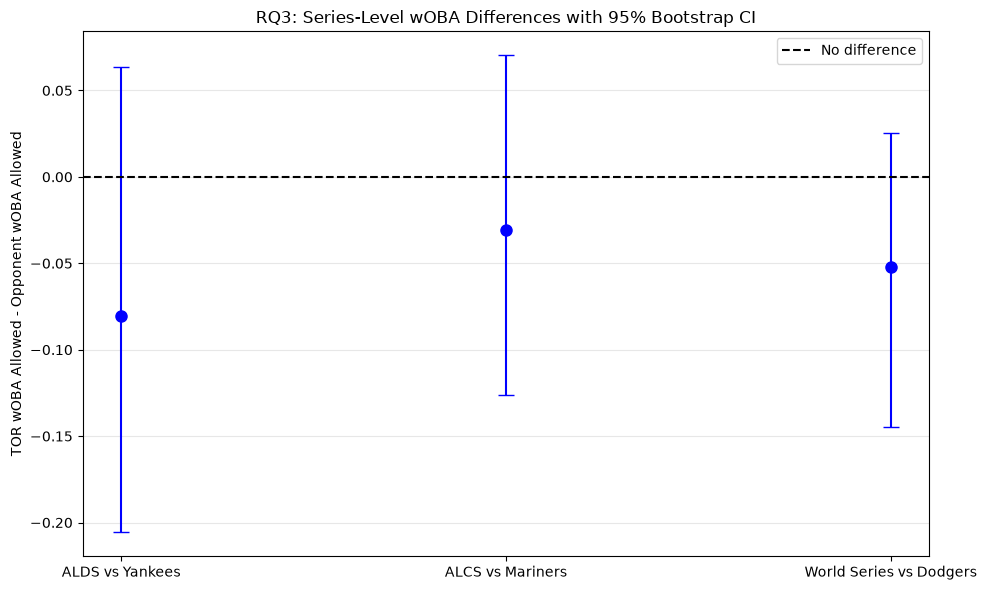

In [78]:
series_order = [
    "ALDS vs Yankees",
    "ALCS vs Mariners",
    "World Series vs Dodgers"
]

rq3_results = (
    rq3_results.set_index("Series")
    .loc[series_order]
    .reset_index()
)
plt.figure(figsize=(10, 6))

x = np.arange(len(rq3_results))

plt.errorbar(
    x,
    rq3_results["Observed Difference"],
    yerr=[
        rq3_results["Observed Difference"] - rq3_results["CI Lower"],
        rq3_results["CI Upper"] - rq3_results["Observed Difference"]
    ],
    fmt="o",
    capsize=6,
    color="blue",
    markersize=8
)

plt.axhline(
    0,
    color="black",
    linestyle="--",
    label="No difference"
)

plt.xticks(x, rq3_results["Series"])
plt.ylabel("TOR wOBA Allowed - Opponent wOBA Allowed")
plt.title("RQ3: Series-Level wOBA Differences with 95% Bootstrap CI")

plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Statistical findings on RQ3 - Series comparisons

Toronto recorded lower wOBA allowed than its opponents in all three
postseason series.

However, the 95% game-level bootstrap confidence intervals included
zero in every series. Therefore, we cannot confidently conclude that
Toronto's underlying pitching performance was better than its
opponents based on these results alone.

The small number of games in each series limits the reliability
of these comparisons.

In [79]:
import numpy as np
import pandas as pd

# Only pitchers with at least 20 qualifying PA
qualified = pitcher_salary[
    pitcher_salary["total_pa_faced"] >= 20
].copy()

# Use non-Toronto pitchers as the benchmark population
peers = qualified[
    qualified["pitching_team"] != "TOR"
].copy()

tor = qualified[
    qualified["pitching_team"] == "TOR"
].copy()

# V1: Salary quartile median
_, bins = pd.qcut(
    peers["salary_usd"],
    q=4,
    retbins=True,
    duplicates="drop"
)

bins[0] = -np.inf
bins[-1] = np.inf

peers["salary_group"] = pd.cut(
    peers["salary_usd"], bins=bins
)

tor["salary_group"] = pd.cut(
    tor["salary_usd"], bins=bins
)

medians = peers.groupby(
    "salary_group", observed=True
)["woba_allowed"].median()

tor["benchmark_v1"] = (
    tor["salary_group"].map(medians).astype(float)
)

# V2 and V3: 10 nearest-salary external peers
def calculate_peer_benchmarks(player):

    closest = peers.copy()

    closest["salary_gap"] = abs(
        closest["salary_usd"] - player["salary_usd"]
    )

    closest = closest.sort_values(
        ["salary_gap", "pitcher"]
    ).head(10)

    return pd.Series({
        "benchmark_v2": closest["woba_allowed"].median(),
        "benchmark_v3": np.average(
            closest["woba_allowed"],
            weights=closest["total_pa_faced"]
        )
    })

tor[["benchmark_v2", "benchmark_v3"]] = (
    tor.apply(calculate_peer_benchmarks, axis=1)
)

# Calculate scores for all three benchmarks
for v in [1, 2, 3]:
    tor[f"score_v{v}"] = (
        tor["woba_allowed"] - tor[f"benchmark_v{v}"]
    )

# Count favorable benchmarks
score_cols = ["score_v1", "score_v2", "score_v3"]

tor["favorable_count"] = (
    (tor[score_cols] < 0).sum(axis=1)
)

# Include all 15 Toronto pitchers
rq1_final = pitcher_salary[
    pitcher_salary["pitching_team"] == "TOR"
][[
    "pitcher", "full_name", "salary_usd",
    "total_pa_faced", "woba_allowed"
]].merge(
    tor[[
        "pitcher",
        "benchmark_v1", "score_v1",
        "benchmark_v2", "score_v2",
        "benchmark_v3", "score_v3",
        "favorable_count"
    ]],
    on="pitcher",
    how="left",
    validate="one_to_one"
)

rq1_final["status"] = rq1_final.apply(
    lambda row: (
        f"{int(row['favorable_count'])}/3 favorable"
        if row["total_pa_faced"] >= 20
        else "Not benchmarked (<20 PA)"
    ),
    axis=1
)

rq1_final.sort_values(
    ["favorable_count", "score_v3"],
    ascending=[False, True]
)


,pitcher,full_name,salary_usd,total_pa_faced,woba_allowed,benchmark_v1,score_v1,benchmark_v2,score_v2,benchmark_v3,score_v3,favorable_count,status
2,605135,Chris Bassitt,22000000.0,30.0,0.136667,0.287500,-0.150833,0.285108,-0.148441,0.286722,-0.150056,3.0,3/3 favorable
5,656546,Jeff Hoffman,7666667.0,46.0,0.209783,0.347959,-0.138177,0.328594,-0.118811,0.298246,-0.088463,3.0,3/3 favorable
1,592332,Kevin Gausman,23000000.0,116.0,0.239224,0.287500,-0.048276,0.285108,-0.045884,0.286722,-0.047498,3.0,3/3 favorable
4,641778,Eric Lauer,1797849.0,33.0,0.216667,0.269811,-0.053145,0.269281,-0.052614,0.261025,-0.044358,3.0,3/3 favorable
3,622554,Seranthony Domínguez,8000000.0,49.0,0.308163,0.347959,-0.039796,0.328594,-0.020430,0.298246,0.009918,2.0,2/3 favorable
0,453286,Max Scherzer,15500000.0,58.0,0.327586,0.287500,0.040086,0.351326,-0.023740,0.293939,0.033647,1.0,1/3 favorable
14,702056,Trey Yesavage,760000.0,106.0,0.273585,0.234615,0.038970,0.235795,0.037789,0.268657,0.004928,0.0,0/3 favorable
12,686973,Louis Varland,768150.0,65.0,0.315385,0.234615,0.080769,0.257543,0.057842,0.300339,0.015046,0.0,0/3 favorable
8,669456,Shane Bieber,10000000.0,82.0,0.354268,0.287500,0.066768,0.347959,0.006309,0.308668,0.045600,0.0,0/3 favorable
10,680755,Braydon Fisher,760000.0,31.0,0.422581,0.234615,0.187965,0.235795,0.186785,0.268657,0.153924,0.0,0/3 favorable


For RQ1 v1, v2 and v3 Final table. Nance, Bruihl and Rodrigues all have less than 20 PA faced, therefore they are not benchmarked but will appear on the dashboard with a smaller sample size. 

In [80]:
rq1_final.to_csv(
    "dashboard_rq1_pitcher_benchmarks.csv",
    index=False
)

In [81]:
# RQ2: All Toronto pitchers and workload comparisons
tor_workload.to_csv(
    "dashboard_rq2_workload.csv",
    index=False
)

workload_pairs.to_csv(
    "dashboard_rq2_comparable_pairs.csv",
    index=False
)

# RQ2: Gausman vs. Yesavage bootstrap
pd.DataFrame([{
    "comparison": "Gausman vs Yesavage",
    "observed_difference": observed_diff,
    "ci_lower": ci_lower,
    "ci_upper": ci_upper
}]).to_csv(
    "dashboard_rq2_bootstrap.csv",
    index=False
)

# RQ3: Individual pitchers within each series
pitcher_series.to_csv(
    "dashboard_rq3_pitchers.csv",
    index=False
)

# RQ3: Team-level performance
team_series.to_csv(
    "dashboard_rq3_teams.csv",
    index=False
)

# RQ3: Statistical uncertainty
rq3_results.to_csv(
    "dashboard_rq3_bootstrap.csv",
    index=False
)

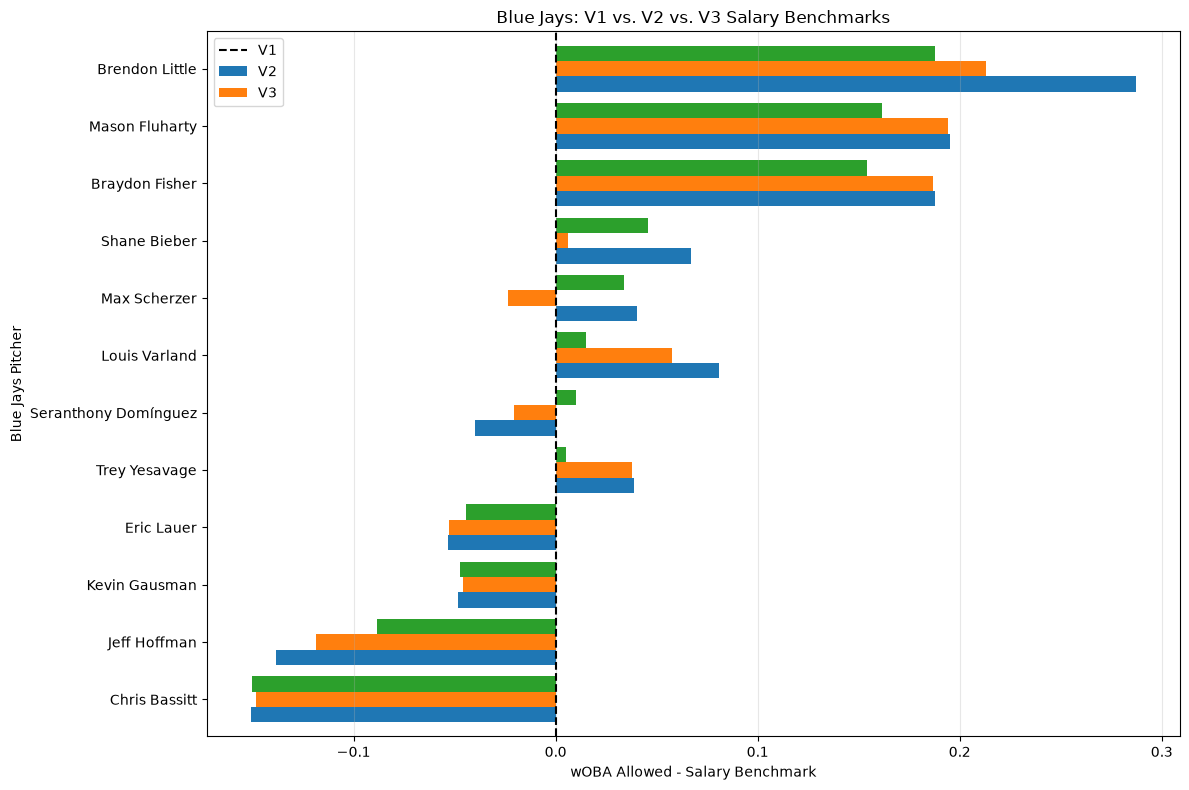

In [82]:
# Compare V1, V2, and V3 salary benchmark scores

plot_data = rq1_final.dropna(
    subset=["score_v1", "score_v2", "score_v3"]
).copy()

plot_data = plot_data.sort_values("score_v3")

plot_data.set_index("full_name")[
    ["score_v1", "score_v2", "score_v3"]
].plot(
    kind="barh",
    figsize=(12, 8),
    width=0.8
)

plt.axvline(0, color="black", linestyle="--")

plt.xlabel("wOBA Allowed - Salary Benchmark")
plt.ylabel("Blue Jays Pitcher")
plt.title("Blue Jays: V1 vs. V2 vs. V3 Salary Benchmarks")

plt.legend(["V1", "V2", "V3"])
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

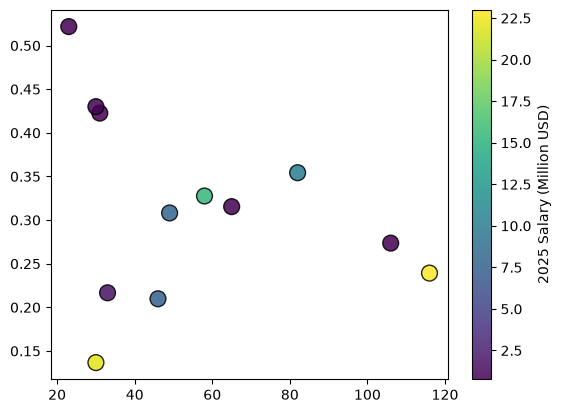

In [83]:
scatter = plt.scatter(
    tor_qualified["total_pa_faced"],
    tor_qualified["woba_allowed"],
    c=tor_qualified["salary_usd"] / 1_000_000,
    cmap="viridis",
    s=130,
    alpha=0.85,
    edgecolors="black"
)

plt.colorbar(scatter, label="2025 Salary (Million USD)")

## Conclusion and Next Steps

We completed three analyses evaluating the Toronto Blue Jays' 2025 postseason pitching performance.

- RQ1 — Salary Efficiency: Compared Blue Jays pitchers against similarly paid postseason pitchers using three benchmarking methods (V1, V2, V3). Spearman's correlation showed no statistically significant relationship between salary and postseason wOBA allowed.
- RQ2 — Workload Comparison: Compared Blue Jays pitchers with similar qualifying plate appearances and used bootstrapping to evaluate uncertainty in performance differences.
- RQ3 — Series-Level Analysis: Compared Toronto's pitching performance against the Yankees, Mariners, and Dodgers. Toronto recorded lower wOBA allowed in all three series, although the bootstrap confidence intervals included zero.

### Limitations
Our results are based on a single postseason, with relatively small sample sizes. Differences in workload, opponents, and salary data sources should be considered when interpreting the findings.

### Next Steps
The analysis results will be integrated into an interactive dashboard, allowing users to explore individual pitchers, salary benchmarks, workload comparisons, and series-level performance.

The final report will bring these findings together and discuss potential recommendations for the Blue Jays.